# HRRR

In [15]:
from functions import *  # get_latest_forecast_cycle, calculate_forecast_range, convert_time_to_datetime64
from herbie import FastHerbie
import pandas as pd
import xarray as xr
import numpy as np
import warnings
import json
import subprocess
from pathlib import Path
from datetime import datetime, timezone
from PIL import Image, ImageDraw
import warnings

# Suppress the specific FutureWarning message from cfgrib
warnings.filterwarnings(
    "ignore",
    # message="In a future version of xarray the default value for compat will change",
    message="In*",
    category=FutureWarning
)

# Silence a specific non-actionable warning emitted by xarray plugins
warnings.filterwarnings("ignore", message="Engine 'gini' loading failed.*", category=RuntimeWarning)

# -------------------------------------------------------------------
# Paths and constants
# -------------------------------------------------------------------

# Single point to summarize (longitude, latitude)
# cityName = "Loveland, CO (KFNL)"
# points = pd.DataFrame({"longitude": [-105.004186], "latitude": [40.451685]})
cityName = 'Kansas City, MO (KMCI)'
points = pd.DataFrame({"longitude": [-94.711], "latitude": [39.301]})


# ISO timestamp (UTC) for metadata and git commit message
now_iso = datetime.now(timezone.utc).replace(microsecond=0).isoformat()

# -------------------------
# HRRR (inline)
# -------------------------
print("Fetching HRRR data...")

# Determine the latest model cycle (uses functions.get_latest_forecast_cycle)
init_hrrr = get_latest_forecast_cycle(model="HRRR")

# Determine forecast steps to request (uses functions.calculate_forecast_range)
fxx_hrrr = calculate_forecast_range(init_hrrr, model="HRRR")

# Request fields from Herbie
H_hrrr = FastHerbie([init_hrrr], model="hrrr", product="sfc", fxx=fxx_hrrr)

# 2 m temperature: extract, convert K->F, compute max/min for the point
t2m_hrrr = H_hrrr.xarray("TMP:2 m above", backend_kwargs={'decode_times': False}
                        ).herbie.pick_points(points, method="nearest")['t2m'].sel(point=0)  
t2m_hrrr = (t2m_hrrr - 273.15) * 1.8 + 32
tmax_hrrr = float(t2m_hrrr.max().values)
tmin_hrrr = float(t2m_hrrr.min().values)
init_times_hrrr = convert_time_to_datetime64(t2m_hrrr.time.values)
valid_times_hrrr = convert_time_to_datetime64(t2m_hrrr.valid_time.values)

# 10 m wind speed (HRRR exposes :WIND / si10)
si10_hrrr = H_hrrr.xarray(":WIND", backend_kwargs={'decode_times': False}
                            ).herbie.pick_points(points, method="nearest")['max_10si'].sel(point=0) 
wind_max_hrrr = float(si10_hrrr.max().values) * 1.94384

# Total precipitation from APCP (convert mm -> in); compute 24h accumulation as in prior script
tp_hrrr = H_hrrr.xarray("APCP", backend_kwargs={'decode_times': False}
                        ).herbie.pick_points(points, method="nearest")['tp'].sel(point=0)
tp_hrrr = tp_hrrr * 0.0393701   # mm -> inches (1 mm -> 0.0393701 in)

# Subtract first timestep to get accumulation over the requested period (as in original)
tp_hrrr = tp_hrrr - tp_hrrr[0]
precip_hrrr = float(tp_hrrr.max().values)


Fetching HRRR data...


In [2]:
init_hrrr, fxx_hrrr, 17+12

(Timestamp('2025-09-20 12:00:00'),
 [18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38,
  39,
  40,
  41,
  42],
 29)

In [8]:
convert_time_to_datetime64(H_hrrr.xarray("APCP", backend_kwargs={'decode_times': False})['valid_time'].values)



array(['2025-09-21T06', '2025-09-21T07', '2025-09-21T08', '2025-09-21T09',
       '2025-09-21T10', '2025-09-21T11', '2025-09-21T12', '2025-09-21T13',
       '2025-09-21T14', '2025-09-21T15', '2025-09-21T16', '2025-09-21T17',
       '2025-09-21T18', '2025-09-21T19', '2025-09-21T20', '2025-09-21T21',
       '2025-09-21T22', '2025-09-21T23', '2025-09-22T00', '2025-09-22T01',
       '2025-09-22T02', '2025-09-22T03', '2025-09-22T04', '2025-09-22T05',
       '2025-09-22T06'], dtype='datetime64[h]')

In [5]:
tp_hrrr = H_hrrr.xarray("APCP", backend_kwargs={'decode_times': False}
                        ).herbie.pick_points(points, method="nearest")['tp'].sel(point=0)
tp_hrrr = tp_hrrr * 0.0393701   # mm -> inches (1 mm -> 0.0393701 in)

# Subtract first timestep to get accumulation over the requested period (as in original)
tp_hrrr = tp_hrrr - tp_hrrr[0]
precip_hrrr = float(tp_hrrr.max().values)


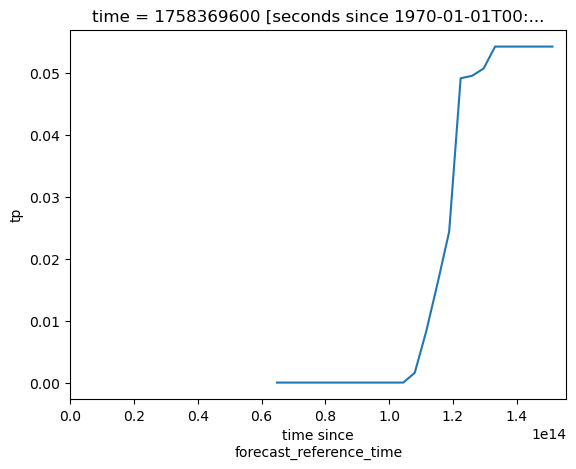

In [6]:
tp_hrrr.plot(xlim=0)

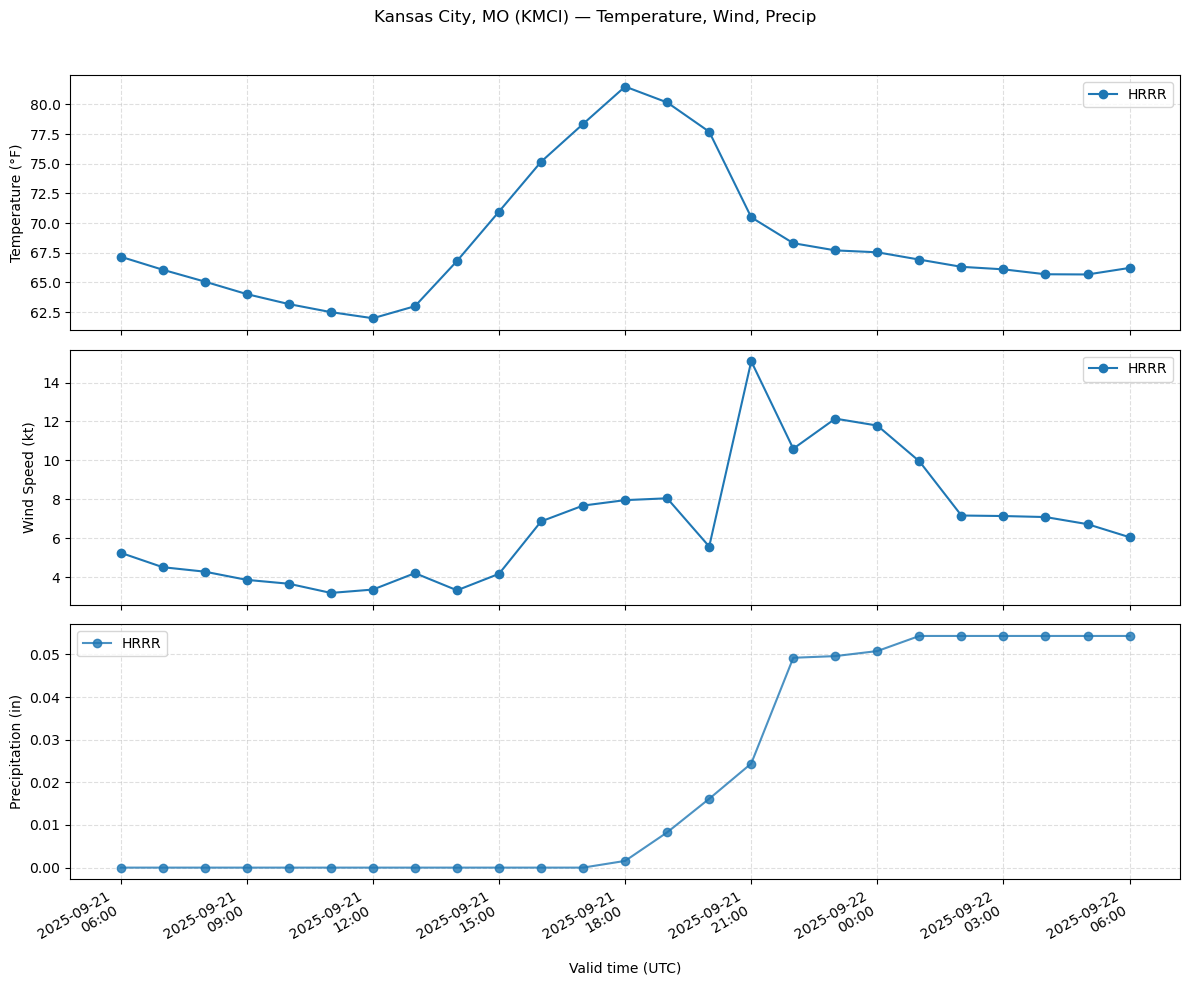

In [16]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

def to_1d(x):
    try:
        x = x.sel(point=0)
    except Exception:
        pass
    return np.asarray(x).flatten()

# --- prepare time series for each model ---
times_hrrr = pd.to_datetime(valid_times_hrrr)
temps_hrrr = to_1d(t2m_hrrr)
wind_hrrr = to_1d(si10_hrrr) * 1.94384
precip_hrrr = to_1d(tp_hrrr)  # already converted to inches and processed earlier

# times_ifs = pd.to_datetime(valid_times_ifs)
# temps_ifs = to_1d(t2m_ifs)
# wind_ifs = to_1d(np.sqrt(u10_ifs**2 + v10_ifs**2)) * 1.94384
# # convert IFS tp (mm -> in) and compute accumulation inside the window (match other models)
# precip_ifs = tp_ifs.values * 39.3701

# times_aifs = pd.to_datetime(valid_times_aifs)
# temps_aifs = to_1d(t2m_aifs)
# wind_aifs = to_1d(np.sqrt(u10_aifs**2 + v10_aifs**2)) * 1.94384
# # convert AIFS tp (mm -> in) and compute accumulation inside the window (match other models)
# precip_aifs = tp_aifs.values * 0.0393701

# times_gfs = pd.to_datetime(valid_times_gfs)
# temps_gfs = to_1d(t2m_f)
# wind_gfs = to_1d(np.sqrt(u10**2 + v10**2)) * 1.94384
# precip_gfs = to_1d(tp_gfs)  # already converted to inches and processed earlier

# --- create combined 3-panel figure ---
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

# Temperature
ax = axes[0]
ax.plot(times_hrrr, temps_hrrr, marker='o', linestyle='-', color='C0', label='HRRR')
# ax.plot(times_ifs, temps_ifs, marker='o', linestyle='-', color='C1', label='IFS')
# ax.plot(times_gfs, temps_gfs, marker='o', linestyle='-', color='C2', label='GFS')
# ax.plot(times_aifs, temps_aifs, marker='o', linestyle='-', color='C3', label='AIFS')
ax.set_ylabel("Temperature (°F)")
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='best')

# Wind
ax = axes[1]
ax.plot(times_hrrr, wind_hrrr, marker='o', linestyle='-', color='C0', label='HRRR')
# ax.plot(times_ifs, wind_ifs, marker='o', linestyle='-', color='C1', label='IFS')
# ax.plot(times_gfs, wind_gfs, marker='o', linestyle='-', color='C2', label='GFS')
# ax.plot(times_aifs, wind_aifs, marker='o', linestyle='-', color='C3', label='AIFS')
ax.set_ylabel("Wind Speed (kt)")
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='best')

# Precipitation (line plot)
ax = axes[2]
ax.plot(times_hrrr, precip_hrrr, marker='o', linestyle='-', color='C0', label='HRRR', alpha=0.8)
# ax.plot(times_ifs, precip_ifs, marker='o', linestyle='-', color='C1', label='IFS', alpha=0.8)
# ax.plot(times_gfs, precip_gfs, marker='o', linestyle='-', color='C2', label='GFS', alpha=0.8)
# ax.plot(times_aifs, precip_aifs, marker='o', linestyle='-', color='C3', label='AIFS', alpha=0.8)
ax.set_ylabel("Precipitation (in)")
ax.set_xlabel("Valid time (UTC)")
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='best')

# format x-axis
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d\n%H:%M'))
plt.setp(axes[-1].xaxis.get_majorticklabels(), rotation=30, ha='right')
plt.suptitle(f"{cityName} — Temperature, Wind, Precip", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.96])


# GFS

In [54]:
from functions import *  # get_latest_forecast_cycle, calculate_forecast_range, convert_time_to_datetime64
from herbie import FastHerbie
import pandas as pd
import xarray as xr
import numpy as np
import warnings
import json
import subprocess
from pathlib import Path
from datetime import datetime, timezone
from PIL import Image, ImageDraw
import warnings

# Suppress the specific FutureWarning message from cfgrib
warnings.filterwarnings(
    "ignore",
    # message="In a future version of xarray the default value for compat will change",
    message="In*",
    category=FutureWarning
)

# Silence a specific non-actionable warning emitted by xarray plugins
warnings.filterwarnings("ignore", message="Engine 'gini' loading failed.*", category=RuntimeWarning)

# -------------------------------------------------------------------
# Paths and constants
# -------------------------------------------------------------------

# Single point to summarize (longitude, latitude)
# cityName = "Loveland, CO (KFNL)"
# points = pd.DataFrame({"longitude": [-105.004186], "latitude": [40.451685]})
cityName = 'Kansas City, MO (KMCI)'
points = pd.DataFrame({"longitude": [-94.711], "latitude": [39.301]})
cityName = 'Springfield, IL (KSPI)'
points = pd.DataFrame({"longitude": [-89.6167], "latitude": [39.8442]})


# ISO timestamp (UTC) for metadata and git commit message
now_iso = datetime.now(timezone.utc).replace(microsecond=0).isoformat()


print("Fetching GFS data...")

# determine latest cycle & forecast range for GFS
init_gfs = get_latest_forecast_cycle(model="GFS")
fxx_gfs = calculate_forecast_range(init_gfs, model="GFS")

# request fields (product string may vary by deployment; adjust if needed)
H_gfs = FastHerbie([init_gfs], model="gfs", product="pgrb2.0p25", fxx=fxx_gfs)

# 2 m temperature -> convert K to °F
t2m_gfs = H_gfs.xarray("TMP:2 m above", backend_kwargs={'decode_times': False}
                ).herbie.pick_points(points, method="nearest")['t2m'].sel(point=0)
t2m_f = (t2m_gfs - 273.15) * 9.0/5.0 + 32.0
tmax_gfs = float(t2m_f.max().values)
tmin_gfs = float(t2m_f.min().values)
init_times_gfs = convert_time_to_datetime64(t2m_gfs.time.values)
valid_times_gfs = convert_time_to_datetime64(t2m_gfs.valid_time.values)

# wind components -> magnitude (m/s -> kt)
u10 = H_gfs.xarray("UGRD:10 m above ground", backend_kwargs={'decode_times': False}
                ).herbie.pick_points(points, method="nearest")['u10']
v10 = H_gfs.xarray("VGRD:10 m above ground", backend_kwargs={'decode_times': False}
                ).herbie.pick_points(points, method="nearest")['v10']
wind_max_gfs = float((np.sqrt(u10**2 + v10**2)).max().values) * 1.94384

# total precipitation (sum over steps) -> convert mm -> inches
# tp = H.xarray(":tp:", backend_kwargs={'decode_times': False}
#                 ).herbie.pick_points(points, method="nearest")['tp'].sel(point=0)
# precip_in = float(tp.sum().values) * 0.0393701
# Total precipitation from APCP (convert mm -> in); compute 24h accumulation as in prior script
tp_gfs = H_gfs.xarray(":APCP:surface:0-*", backend_kwargs={'decode_times': False}
                        ).herbie.pick_points(points, method="nearest")['tp'].sel(point=0)
tp_gfs = tp_gfs * 0.0393701   # mm -> inches (1 mm -> 0.0393701 in)

# Subtract first timestep to get accumulation over the requested period (as in original)
tp_gfs = tp_gfs - tp_gfs[0]
precip_gfs = float(tp_gfs.max().values)


Fetching GFS data...


In [30]:
init_gfs, fxx_gfs, 12+18, valid_times_gfs


(Timestamp('2025-09-20 12:00:00'),
 [18, 21, 24, 27, 30, 33, 36, 39, 42],
 30,
 array(['2025-09-21T06', '2025-09-21T09', '2025-09-21T12', '2025-09-21T15',
        '2025-09-21T18', '2025-09-21T21', '2025-09-22T00', '2025-09-22T03',
        '2025-09-22T06'], dtype='datetime64[h]'))

In [ ]:
H.inventory(":APCP:surface:0-*")


,grib_message,start_byte,end_byte,range,reference_time,valid_time,variable,level,forecast_time,search_this,FILE
0,597,419438114,419930301.0,419438114-419930301,2025-09-20 12:00:00,2025-09-21 06:00:00,APCP,surface,0-18 hour acc fcst,:APCP:surface:0-18 hour acc fcst,https://noaa-gfs-bdp-pds.s3.amazonaws.com/gfs....
1,597,419480782,419990320.0,419480782-419990320,2025-09-20 12:00:00,2025-09-21 09:00:00,APCP,surface,0-21 hour acc fcst,:APCP:surface:0-21 hour acc fcst,https://noaa-gfs-bdp-pds.s3.amazonaws.com/gfs....
2,597,417840351,418365260.0,417840351-418365260,2025-09-20 12:00:00,2025-09-21 12:00:00,APCP,surface,0-1 day acc fcst,:APCP:surface:0-1 day acc fcst,https://noaa-gfs-bdp-pds.s3.amazonaws.com/gfs....
3,597,420088296,420627927.0,420088296-420627927,2025-09-20 12:00:00,2025-09-21 15:00:00,APCP,surface,0-27 hour acc fcst,:APCP:surface:0-27 hour acc fcst,https://noaa-gfs-bdp-pds.s3.amazonaws.com/gfs....
4,597,419073527,419627365.0,419073527-419627365,2025-09-20 12:00:00,2025-09-21 18:00:00,APCP,surface,0-30 hour acc fcst,:APCP:surface:0-30 hour acc fcst,https://noaa-gfs-bdp-pds.s3.amazonaws.com/gfs....
5,597,422079118,422645916.0,422079118-422645916,2025-09-20 12:00:00,2025-09-21 21:00:00,APCP,surface,0-33 hour acc fcst,:APCP:surface:0-33 hour acc fcst,https://noaa-gfs-bdp-pds.s3.amazonaws.com/gfs....
6,597,421152284,421731332.0,421152284-421731332,2025-09-20 12:00:00,2025-09-22 00:00:00,APCP,surface,0-36 hour acc fcst,:APCP:surface:0-36 hour acc fcst,https://noaa-gfs-bdp-pds.s3.amazonaws.com/gfs....
7,597,422220580,422810155.0,422220580-422810155,2025-09-20 12:00:00,2025-09-22 03:00:00,APCP,surface,0-39 hour acc fcst,:APCP:surface:0-39 hour acc fcst,https://noaa-gfs-bdp-pds.s3.amazonaws.com/gfs....
8,597,420697866,421297946.0,420697866-421297946,2025-09-20 12:00:00,2025-09-22 06:00:00,APCP,surface,0-42 hour acc fcst,:APCP:surface:0-42 hour acc fcst,https://noaa-gfs-bdp-pds.s3.amazonaws.com/gfs....


In [53]:
xr.open_dataset('/Users/jglarson/Downloads/gfs.t12z.pgrb2.0p25.f018', engine='cfgrib', filter_by_keys={'typeOfLevel': 'surface', 'stepType': 'accum', 'typeOfLevel': 'surface'})

<xarray.Dataset> Size: 12MB
Dimensions:     (latitude: 721, longitude: 1440)
Coordinates:
    time        datetime64[ns] 8B ...
    step        timedelta64[ns] 8B ...
    surface     float64 8B ...
  * latitude    (latitude) float64 6kB 90.0 89.75 89.5 ... -89.5 -89.75 -90.0
  * longitude   (longitude) float64 12kB 0.0 0.25 0.5 0.75 ... 359.2 359.5 359.8
    valid_time  datetime64[ns] 8B ...
Data variables:
    tp          (latitude, longitude) float32 4MB ...
    acpcp       (latitude, longitude) float32 4MB ...
    watr        (latitude, longitude) float32 4MB ...
Attributes:
    GRIB_edition:            2
    GRIB_centre:             kwbc
    GRIB_centreDescription:  US National Weather Service - NCEP
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             US National Weather Service - NCEP
    history:                 2025-09-20T12:01 GRIB to CDM+CF via cfgrib-0.9.1...

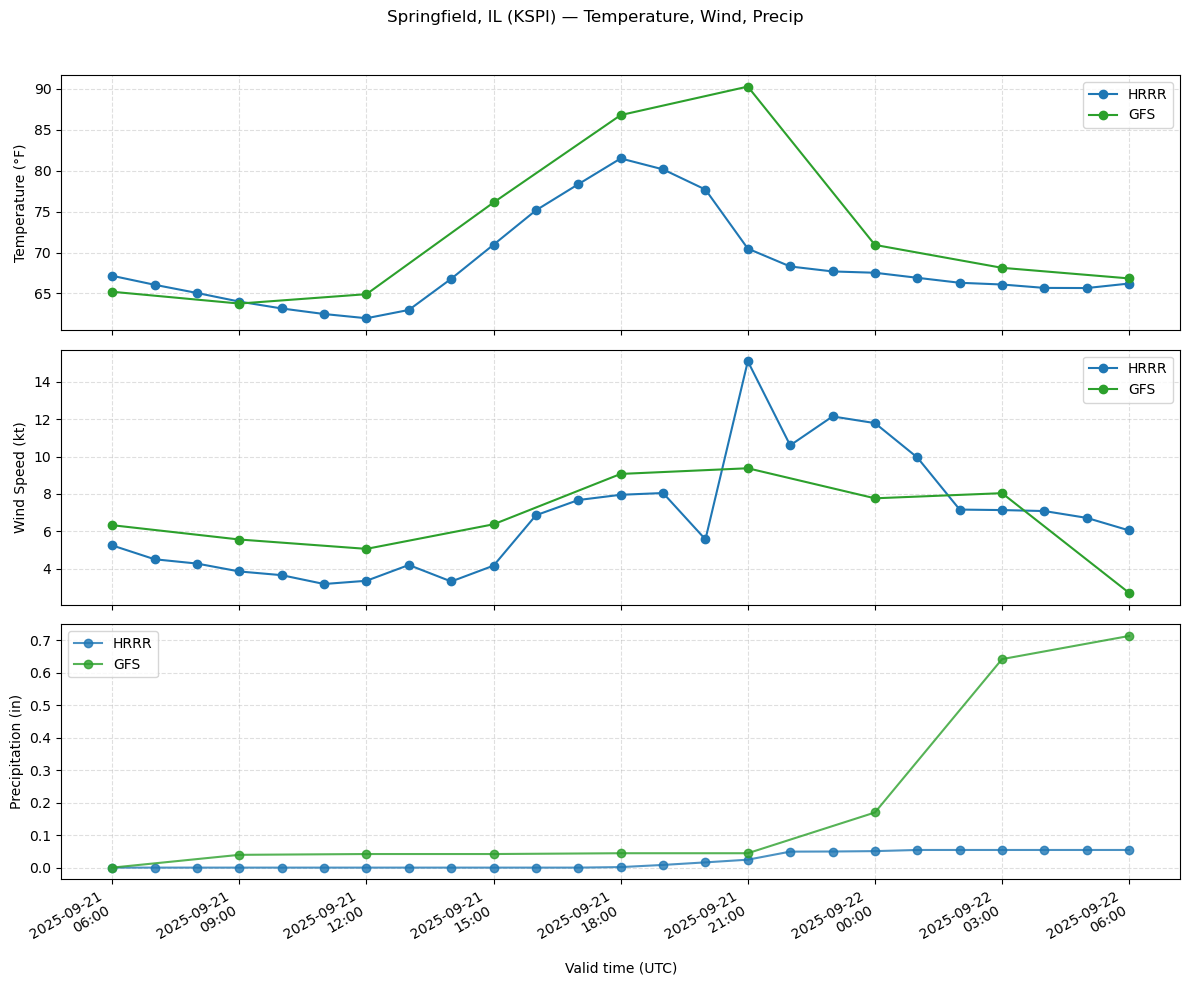

In [55]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

def to_1d(x):
    try:
        x = x.sel(point=0)
    except Exception:
        pass
    return np.asarray(x).flatten()

# --- prepare time series for each model ---
times_hrrr = pd.to_datetime(valid_times_hrrr)
temps_hrrr = to_1d(t2m_hrrr)
wind_hrrr = to_1d(si10_hrrr) * 1.94384
precip_hrrr = to_1d(tp_hrrr)  # already converted to inches and processed earlier

# times_ifs = pd.to_datetime(valid_times_ifs)
# temps_ifs = to_1d(t2m_ifs)
# wind_ifs = to_1d(np.sqrt(u10_ifs**2 + v10_ifs**2)) * 1.94384
# # convert IFS tp (mm -> in) and compute accumulation inside the window (match other models)
# precip_ifs = tp_ifs.values * 39.3701

# times_aifs = pd.to_datetime(valid_times_aifs)
# temps_aifs = to_1d(t2m_aifs)
# wind_aifs = to_1d(np.sqrt(u10_aifs**2 + v10_aifs**2)) * 1.94384
# # convert AIFS tp (mm -> in) and compute accumulation inside the window (match other models)
# precip_aifs = tp_aifs.values * 0.0393701

times_gfs = pd.to_datetime(valid_times_gfs)
temps_gfs = to_1d(t2m_f)
wind_gfs = to_1d(np.sqrt(u10**2 + v10**2)) * 1.94384
precip_gfs = to_1d(tp_gfs)  # already converted to inches and processed earlier

# --- create combined 3-panel figure ---
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

# Temperature
ax = axes[0]
ax.plot(times_hrrr, temps_hrrr, marker='o', linestyle='-', color='C0', label='HRRR')
# ax.plot(times_ifs, temps_ifs, marker='o', linestyle='-', color='C1', label='IFS')
ax.plot(times_gfs, temps_gfs, marker='o', linestyle='-', color='C2', label='GFS')
# ax.plot(times_aifs, temps_aifs, marker='o', linestyle='-', color='C3', label='AIFS')
ax.set_ylabel("Temperature (°F)")
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='best')

# Wind
ax = axes[1]
ax.plot(times_hrrr, wind_hrrr, marker='o', linestyle='-', color='C0', label='HRRR')
# ax.plot(times_ifs, wind_ifs, marker='o', linestyle='-', color='C1', label='IFS')
ax.plot(times_gfs, wind_gfs, marker='o', linestyle='-', color='C2', label='GFS')
# ax.plot(times_aifs, wind_aifs, marker='o', linestyle='-', color='C3', label='AIFS')
ax.set_ylabel("Wind Speed (kt)")
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='best')

# Precipitation (line plot)
ax = axes[2]
ax.plot(times_hrrr, precip_hrrr, marker='o', linestyle='-', color='C0', label='HRRR', alpha=0.8)
# ax.plot(times_ifs, precip_ifs, marker='o', linestyle='-', color='C1', label='IFS', alpha=0.8)
ax.plot(times_gfs, precip_gfs, marker='o', linestyle='-', color='C2', label='GFS', alpha=0.8)
# ax.plot(times_aifs, precip_aifs, marker='o', linestyle='-', color='C3', label='AIFS', alpha=0.8)
ax.set_ylabel("Precipitation (in)")
ax.set_xlabel("Valid time (UTC)")
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='best')

# format x-axis
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d\n%H:%M'))
plt.setp(axes[-1].xaxis.get_majorticklabels(), rotation=30, ha='right')
plt.suptitle(f"{cityName} — Temperature, Wind, Precip", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.96])


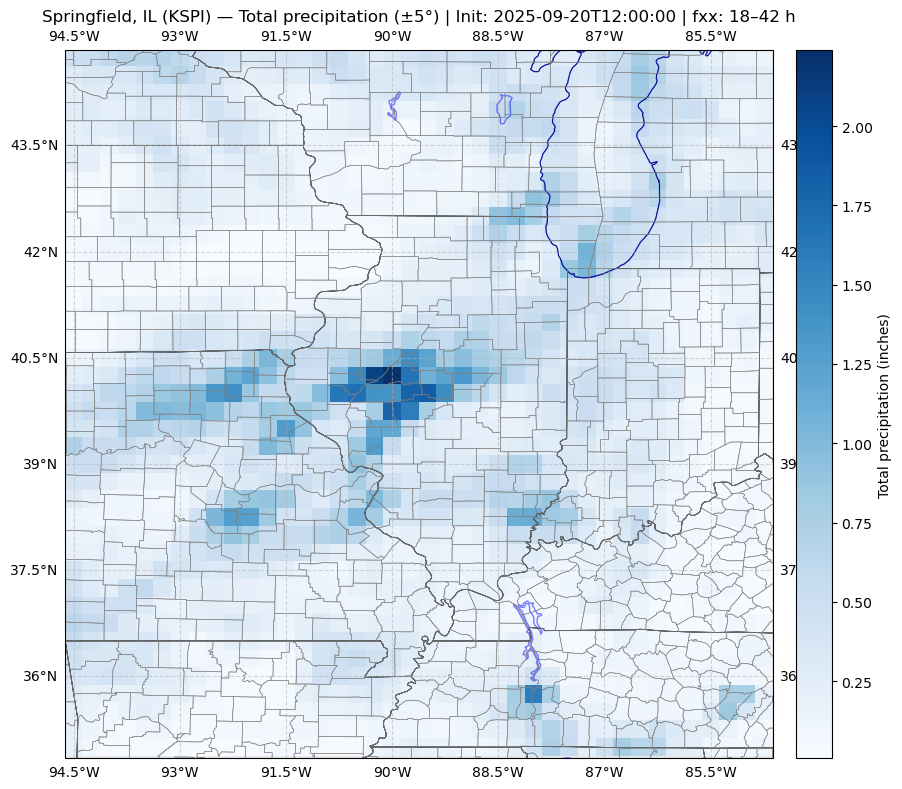

In [60]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.io import shapereader as shpreader

# Fetch gridded total precipitation for the same steps, sum over the steps and plot a subset +/-5° around the point
ds_tp = H_gfs.xarray(":APCP:surface:0-*", backend_kwargs={'decode_times': False}
                        )
da_tp = ds_tp['tp'][-1]

# Sum accumulated precipitation over the step dimension to get total (units: meters)
da_total_in = da_tp * 0.0393701 # Convert meters -> inches

# Center from points dataframe
center_lon = float(points.longitude.iloc[0])
center_lat = float(points.latitude.iloc[0])
lon0, lon1 = center_lon - 5.0, center_lon + 5.0
lat0, lat1 = center_lat - 5.0, center_lat + 5.0

# Normalize longitude to -180..180 if needed
if da_total_in.longitude.max() > 180:
    lons = ((da_total_in.longitude + 180) % 360) - 180
    da_total_in = da_total_in.assign_coords(longitude=lons).sortby('longitude')

# Subset using boolean indexing to avoid issues with coordinate ordering
da_sel = da_total_in.where(
    (da_total_in.longitude >= min(lon0, lon1)) & (da_total_in.longitude <= max(lon0, lon1)),
    drop=True
)
da_sel = da_sel.where(
    (da_sel.latitude >= min(lat0, lat1)) & (da_sel.latitude <= max(lat0, lat1)),
    drop=True
)

# Plot with cartopy for geographic features
fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={'projection': ccrs.PlateCarree()})
# Use xarray's built-in pcolormesh plotting (handles lat/lon coords)
c = da_sel.plot.pcolormesh(
    ax=ax, x='longitude', y='latitude', cmap='Blues', shading='auto', add_colorbar=False, transform=ccrs.PlateCarree()
)
cb = fig.colorbar(c, ax=ax, orientation='vertical', pad=0.02)
cb.set_label('Total precipitation (inches)')

# Add geographic features
ax.add_feature(cfeature.BORDERS, linestyle='--', edgecolor='black', linewidth=0.8)
ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.6)
ax.add_feature(cfeature.COASTLINE, edgecolor='black', linewidth=0.6)
ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.5)
ax.add_feature(cfeature.LAKES, edgecolor='blue', facecolor='none', alpha=0.5)

# Add county boundaries using a shapefile
shapefile = shpreader.natural_earth(resolution='10m', category='cultural', name='admin_2_counties')
counties = shpreader.Reader(shapefile).geometries()
ax.add_geometries(counties, ccrs.PlateCarree(), edgecolor='gray', facecolor='none', linewidth=0.4)

# Set title and labels
ax.set_title(f"{cityName} — Total precipitation (±5°) | Init: {pd.Timestamp(init_gfs).isoformat()} | fxx: {fxx_gfs[0]}–{fxx_gfs[-1]} h")
ax.set_extent([min(lon0, lon1), max(lon0, lon1), min(lat0, lat1), max(lat0, lat1)], crs=ccrs.PlateCarree())
ax.gridlines(draw_labels=True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [59]:
valid_times_gfs

array(['2025-09-21T06', '2025-09-21T09', '2025-09-21T12', '2025-09-21T15',
       '2025-09-21T18', '2025-09-21T21', '2025-09-22T00', '2025-09-22T03',
       '2025-09-22T06'], dtype='datetime64[h]')

# NBM

In [6]:
from functions import *   # get_latest_forecast_cycle, calculate_forecast_range, convert_time_to_datetime64
from herbie import FastHerbie
import pandas as pd
import numpy as np
import xarray as xr
import warnings
import dask

# Suppress the specific FutureWarning message from cfgrib
warnings.filterwarnings(
    "ignore",
    # message="In a future version of xarray the default value for compat will change",
    message="In*",
    category=FutureWarning
)

# xr.set_options(use_new_combine_kwarg_defaults=True)

# xr.set_options(use_new_combine_kwarg_defaults=True)

# single point (longitude, latitude)
cityName = "Loveland, CO (KFNL)"
points = pd.DataFrame({"longitude": [-105.004186], "latitude": [40.451685]})
# cityName = 'Memphis, TN (KMEM)'
# points = pd.DataFrame({"longitude": [-90.04898], "latitude": [35.14953]})
cityName = "Boston, MA (KBOS)"
points = pd.DataFrame({"longitude": [-71.0591], "latitude": [42.3601]})

def selPoint(da, target_lat, target_lon, lat_name="latitude", lon_name="longitude"):
    """
    Select nearest grid cell from a DataArray `da` when latitude/longitude are 2D arrays.
    Returns (point_da, iy, ix, grid_lat, grid_lon).
    """
    import numpy as np

    lat2d = da[lat_name]
    lon2d = da[lon_name]

    # normalize target lon to grid convention (0-360 vs -180..180)
    lon_max = float(lon2d.max().values)
    t_lon = float(target_lon)
    if lon_max > 180 and t_lon < 0:
        t_lon = t_lon + 360
    if lon_max <= 180 and t_lon > 180:
        t_lon = ((t_lon + 180) % 360) - 180

    # compute squared distance (fast); use nanargmin to ignore missing coords
    dist = (lat2d - float(target_lat))**2 + (lon2d - t_lon)**2
    idx_flat = np.nanargmin(dist.values)
    iy, ix = np.unravel_index(idx_flat, dist.shape)

    # point_da = da.isel(y=iy, x=ix)
    # grid_lat = float(lat2d.isel(y=iy, x=ix).values)
    # grid_lon = float(lon2d.isel(y=iy, x=ix).values)
    # return point_da, iy, ix, grid_lat, grid_lon
    return da.isel(y=iy, x=ix)


In [7]:
# Determine the latest model cycle (uses functions.get_latest_forecast_cycle)
init_nbm = get_latest_forecast_cycle(model="IFS")

# Determine forecast steps to request (uses functions.calculate_forecast_range)
fxx_nbm = calculate_forecast_range(init_nbm, model="IFS")

H_nbm = FastHerbie([init_nbm], model="NBM", product="co", fxx=fxx_nbm)

# H_nbm.inventory(":TMP:2 m.*:nan:nan")

In [5]:
init_nbm, fxx_nbm



(Timestamp('2025-09-23 00:00:00'), [30, 33, 36, 39, 42, 45, 48, 51, 54])

In [8]:
H_nbm.inventory(":APCP:")
# H_nbm.inventory(":APCP:surface:29-30 hour acc fcst:nan:nan")
# H_nbm.xarray(":APCP:surface:14-15 hour acc fcst:", backend_kwargs={'decode_times': False})

,grib_message,start_byte,end_byte,range,reference_time,valid_time,variable,level,forecast_time,?,??,???,search_this,FILE
0,65,70880462,71719522.0,70880462-71719522,2025-09-23,2025-09-24 06:00:00,APCP,surface,29-30 hour acc fcst,prob >0.254,prob fcst 255/255,NaN,:APCP:surface:29-30 hour acc fcst:prob >0.254:...,https://nomads.ncep.noaa.gov/pub/data/nccf/com...
1,66,71719523,72648810.0,71719523-72648810,2025-09-23,2025-09-24 06:00:00,APCP,surface,24-30 hour acc fcst,prob >0.254,prob fcst 255/255,NaN,:APCP:surface:24-30 hour acc fcst:prob >0.254:...,https://nomads.ncep.noaa.gov/pub/data/nccf/com...
2,67,72648811,73569079.0,72648811-73569079,2025-09-23,2025-09-24 06:00:00,APCP,surface,18-30 hour acc fcst,prob >0.254,prob fcst 255/255,NaN,:APCP:surface:18-30 hour acc fcst:prob >0.254:...,https://nomads.ncep.noaa.gov/pub/data/nccf/com...
3,78,81728055,82783797.0,81728055-82783797,2025-09-23,2025-09-24 06:00:00,APCP,surface,29-30 hour acc fcst,NaN,NaN,NaN,:APCP:surface:29-30 hour acc fcst:nan:nan,https://nomads.ncep.noaa.gov/pub/data/nccf/com...
4,79,82783798,84341920.0,82783798-84341920,2025-09-23,2025-09-24 06:00:00,APCP,surface,24-30 hour acc fcst,NaN,NaN,NaN,:APCP:surface:24-30 hour acc fcst:nan:nan,https://nomads.ncep.noaa.gov/pub/data/nccf/com...
5,49,61007646,61835282.0,61007646-61835282,2025-09-23,2025-09-24 09:00:00,APCP,surface,32-33 hour acc fcst,prob >0.254,prob fcst 255/255,NaN,:APCP:surface:32-33 hour acc fcst:prob >0.254:...,https://nomads.ncep.noaa.gov/pub/data/nccf/com...
6,57,68084630,69182368.0,68084630-69182368,2025-09-23,2025-09-24 09:00:00,APCP,surface,32-33 hour acc fcst,NaN,NaN,NaN,:APCP:surface:32-33 hour acc fcst:nan:nan,https://nomads.ncep.noaa.gov/pub/data/nccf/com...
7,67,73817497,74637948.0,73817497-74637948,2025-09-23,2025-09-24 12:00:00,APCP,surface,35-36 hour acc fcst,prob >0.254,prob fcst 255/255,NaN,:APCP:surface:35-36 hour acc fcst:prob >0.254:...,https://nomads.ncep.noaa.gov/pub/data/nccf/com...
8,68,74637949,75555576.0,74637949-75555576,2025-09-23,2025-09-24 12:00:00,APCP,surface,30-36 hour acc fcst,prob >0.254,prob fcst 255/255,NaN,:APCP:surface:30-36 hour acc fcst:prob >0.254:...,https://nomads.ncep.noaa.gov/pub/data/nccf/com...
9,69,75555577,76511237.0,75555577-76511237,2025-09-23,2025-09-24 12:00:00,APCP,surface,24-36 hour acc fcst,prob >0.254,prob fcst 255/255,NaN,:APCP:surface:24-36 hour acc fcst:prob >0.254:...,https://nomads.ncep.noaa.gov/pub/data/nccf/com...


In [10]:
H_nbm.xarray(":APCP:surface:").herbie.pick_points(points, method="nearest")


INFO: 🌱 Growing new BallTree...🌳 BallTree grew in 3.3 seconds.
INFO: Saved BallTree to /Users/jglarson/data/BallTree/nbm_2345-1597.pkl


<xarray.Dataset> Size: 244B
Dimensions:              (step: 9, point: 1)
Coordinates:
    time                 datetime64[ns] 8B 2025-09-23
  * step                 (step) timedelta64[ns] 72B 1 days 06:00:00 ... 2 day...
    surface              float64 8B 0.0
    latitude             (point) float64 8B 42.36
    longitude            (point) float64 8B 288.9
    valid_time           (step) datetime64[ns] 72B 2025-09-24T06:00:00 ... 20...
    gribfile_projection  object 8B None
    point_grid_distance  (point) float64 8B 0.9413
    point_longitude      (point) float64 8B -71.06
    point_latitude       (point) float64 8B 42.36
Dimensions without coordinates: point
Data variables:
    tp                   (step, point) float32 36B 57.0 37.0 33.0 ... 0.254 30.0
Attributes:
    GRIB_edition:            2
    GRIB_centre:             kwbc
    GRIB_centreDescription:  US National Weather Service - NCEP
    GRIB_subCentre:          14
    Conventions:             CF-1.7
    institution:             US National Weather Service - NCEP
    model:                   nbm
    product:                 co
    description:             National Blend of Models
    search:                  :APCP:surface:

In [11]:
H_nbm.download(":APCP:surface:")#.herbie.pick_points(points, method="nearest")['tp']

[PosixPath('/Users/jglarson/data/nbm/20250923/subset_8e487de5__blend.t00z.core.f039.co.grib2'),
 PosixPath('/Users/jglarson/data/nbm/20250923/subset_8e617de5__blend.t00z.core.f045.co.grib2'),
 PosixPath('/Users/jglarson/data/nbm/20250923/subset_8e1e7de5__blend.t00z.core.f051.co.grib2'),
 PosixPath('/Users/jglarson/data/nbm/20250923/subset_8e1b0ef6__blend.t00z.core.f033.co.grib2'),
 PosixPath('/Users/jglarson/data/nbm/20250923/subset_8e0ea4c7__blend.t00z.core.f036.co.grib2'),
 PosixPath('/Users/jglarson/data/nbm/20250923/subset_8e60b624__blend.t00z.core.f030.co.grib2'),
 PosixPath('/Users/jglarson/data/nbm/20250923/subset_8ee7ba03__blend.t00z.core.f042.co.grib2'),
 PosixPath('/Users/jglarson/data/nbm/20250923/subset_8e1ce8cd__blend.t00z.core.f048.co.grib2'),
 PosixPath('/Users/jglarson/data/nbm/20250923/subset_8e78ba03__blend.t00z.core.f054.co.grib2')]

In [ ]:
import glob, re

# Note that the date-folder must be updated as needed 
files = glob.glob('/Users/jglarson/data/nbm/20250923/subset*blend.t*z.core.f*.co.grib2')

def _fnum(path):
    m = re.search(r'\.f(\d+)\.co\.grib2$', path)
    return int(m.group(1)) if m else float('inf')

files_sorted = sorted(files, key=_fnum)               # ascending by numeric forecast hour
file_fxx = [_fnum(p) for p in files_sorted]          # list of extracted fxx integers

files_sorted, file_fxx


(['/Users/jglarson/data/nbm/20250923/subset_8e60b624__blend.t00z.core.f030.co.grib2',
  '/Users/jglarson/data/nbm/20250923/subset_8e1b0ef6__blend.t00z.core.f033.co.grib2',
  '/Users/jglarson/data/nbm/20250923/subset_8e0ea4c7__blend.t00z.core.f036.co.grib2',
  '/Users/jglarson/data/nbm/20250923/subset_8e487de5__blend.t00z.core.f039.co.grib2',
  '/Users/jglarson/data/nbm/20250923/subset_8ee7ba03__blend.t00z.core.f042.co.grib2',
  '/Users/jglarson/data/nbm/20250923/subset_8e617de5__blend.t00z.core.f045.co.grib2',
  '/Users/jglarson/data/nbm/20250923/subset_8e1ce8cd__blend.t00z.core.f048.co.grib2',
  '/Users/jglarson/data/nbm/20250923/subset_8e1e7de5__blend.t00z.core.f051.co.grib2',
  '/Users/jglarson/data/nbm/20250923/subset_8e78ba03__blend.t00z.core.f054.co.grib2'],
 [30, 33, 36, 39, 42, 45, 48, 51, 54])

In [24]:
xr.open_dataset('/Users/jglarson/data/nbm/20250923/subset_8e60b624__blend.t00z.core.f030.co.grib2', engine='cfgrib')

<xarray.Dataset> Size: 75MB
Dimensions:     (y: 1597, x: 2345)
Coordinates:
    time        datetime64[ns] 8B ...
    step        timedelta64[ns] 8B ...
    surface     float64 8B ...
    latitude    (y, x) float64 30MB ...
    longitude   (y, x) float64 30MB ...
    valid_time  datetime64[ns] 8B ...
Dimensions without coordinates: y, x
Data variables:
    tp          (y, x) float32 15MB ...
Attributes:
    GRIB_edition:            2
    GRIB_centre:             kwbc
    GRIB_centreDescription:  US National Weather Service - NCEP
    GRIB_subCentre:          14
    Conventions:             CF-1.7
    institution:             US National Weather Service - NCEP
    history:                 2025-09-23T08:54 GRIB to CDM+CF via cfgrib-0.9.1...

In [21]:
selPoint(xr.open_dataset('/Users/jglarson/data/nbm/20250923/subset_8e60b624__blend.t00z.core.f030.co.grib2').tp, 
         points.latitude[0], points.longitude[0]).values

array(57., dtype=float32)

In [ ]:
selPoint(xr.open_dataset('/Users/jglarson/Downloads/blend.t00z.core.f030.co.grib2', 
                engine='cfgrib', filter_by_keys={'stepType': 'accum', 'typeOfLevel': 'surface', 'uvRelativeToGrid': 0}
                ).tp, points.latitude[0], points.longitude[0])

<xarray.DataArray 'tp' ()> Size: 4B
[1 values with dtype=float32]
Coordinates:
    time        datetime64[ns] 8B ...
    step        timedelta64[ns] 8B ...
    surface     float64 8B ...
    latitude    float64 8B 42.36
    longitude   float64 8B 288.9
    valid_time  datetime64[ns] 8B ...
Attributes: (12/34)
    GRIB_paramId:                             228228
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      3744965
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            accum
    ...                                       ...
    GRIB_name:                                Total Precipitation
    GRIB_shortName:                           tp
    GRIB_units:                               kg m**-2
    long_name:                                Total Precipitation
    units:                                    kg m**-2
    standard_name:                            unknown

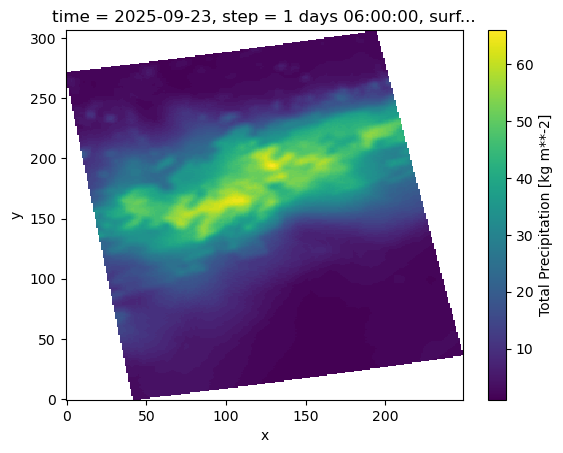

In [47]:
tp = xr.open_dataset('/Users/jglarson/Downloads/blend.t00z.core.f030.co.grib2', 
                engine='cfgrib', filter_by_keys={'stepType': 'accum', 'typeOfLevel': 'surface', 'uvRelativeToGrid': 0}
                )
tp = tp.where((tp.latitude >= 39.0) & (tp.latitude <= 45.0) & (tp.longitude >= 286) & (tp.longitude <= 292), drop=True).tp
tp.plot()

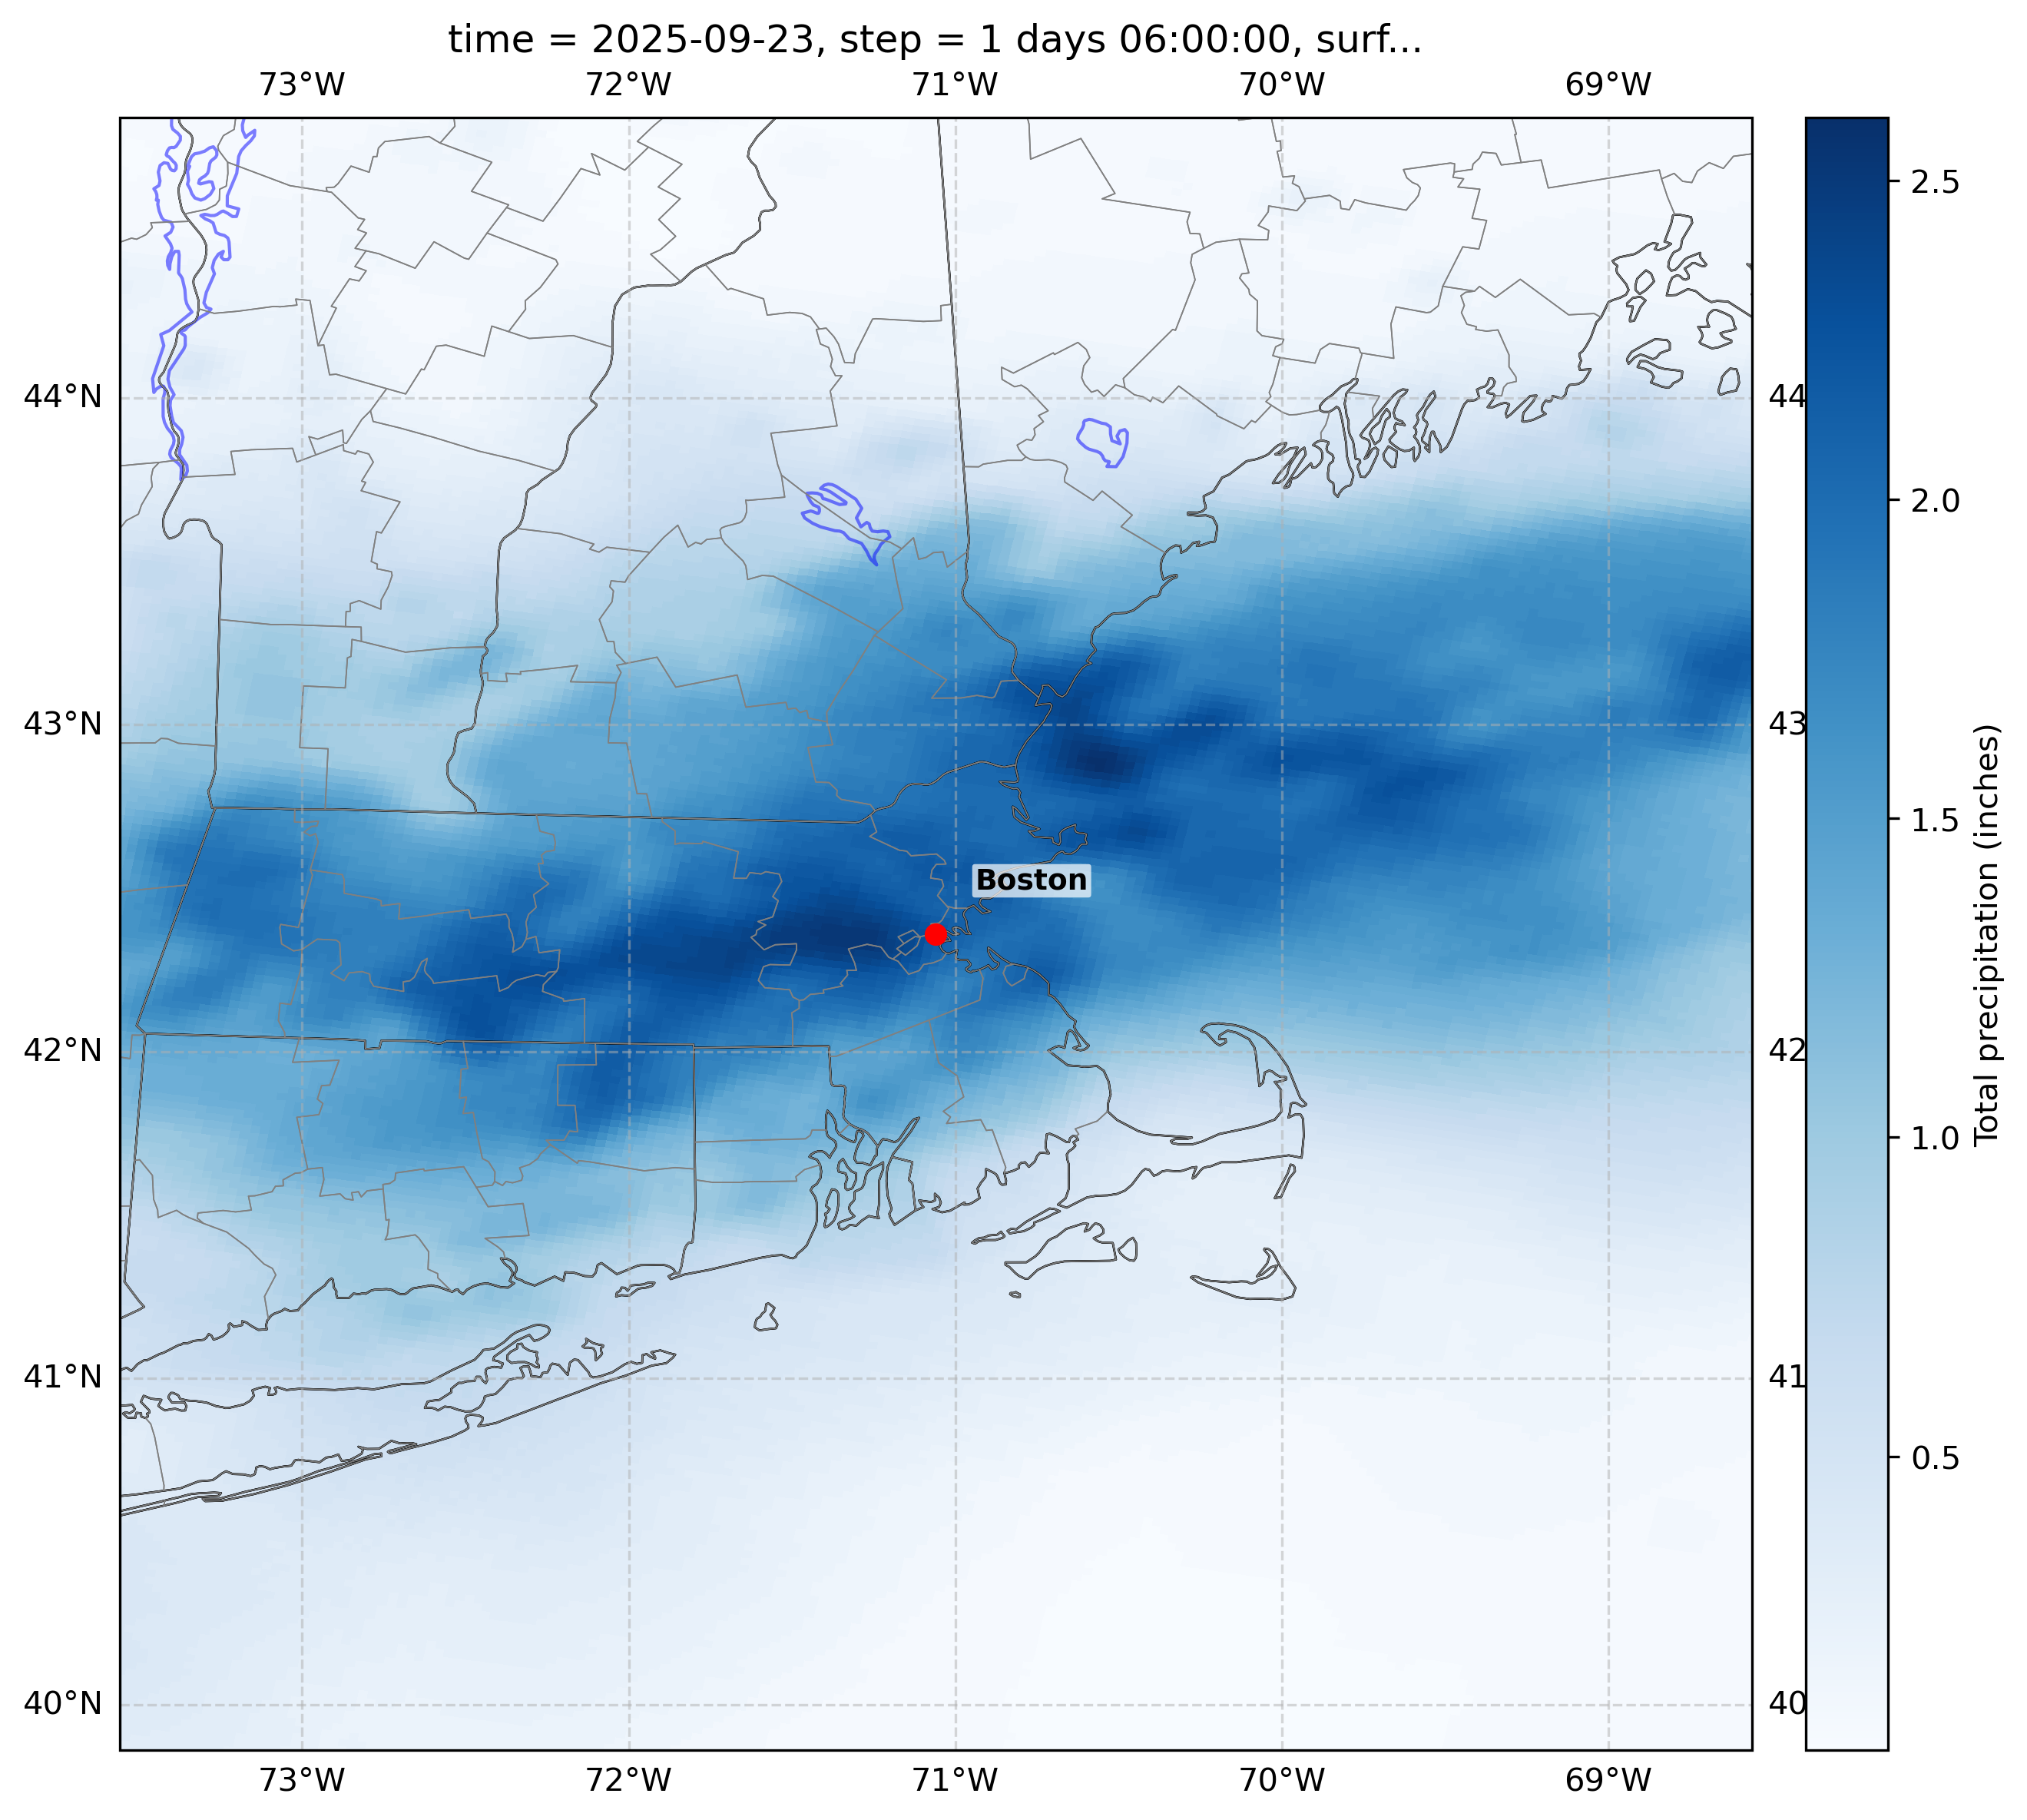

In [55]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.io import shapereader as shpreader

tp = xr.open_dataset('/Users/jglarson/Downloads/blend.t00z.core.f030.co.grib2', 
                engine='cfgrib', filter_by_keys={'stepType': 'accum', 'typeOfLevel': 'surface', 'uvRelativeToGrid': 0}
                )
tp = tp.where((tp.latitude >= 39.0) & (tp.latitude <= 45.0) & (tp.longitude >= 286) & (tp.longitude <= 292), drop=True).tp

da_total_in = tp* 0.0393701  # convert mm -> inches

# Center from points dataframe
center_lon = float(points.longitude.iloc[0])
center_lat = float(points.latitude.iloc[0])
extent = 3 - 0.5
lon0, lon1 = center_lon - extent, center_lon + extent
lat0, lat1 = center_lat - extent, center_lat + extent


# Plot with cartopy for geographic features
fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={'projection': ccrs.PlateCarree()},
                       dpi=300)
# Use xarray's built-in pcolormesh plotting (handles lat/lon coords)
c = da_total_in.plot.pcolormesh(
    ax=ax, x='longitude', y='latitude', cmap='Blues', shading='auto', add_colorbar=False, transform=ccrs.PlateCarree()
)
cb = fig.colorbar(c, ax=ax, orientation='vertical', pad=0.02)
cb.set_label('Total precipitation (inches)')

# Add geographic features
ax.add_feature(cfeature.BORDERS, linestyle='--', edgecolor='black', linewidth=0.8)
ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.6)
ax.add_feature(cfeature.COASTLINE, edgecolor='black', linewidth=0.6)
ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.5)
ax.add_feature(cfeature.LAKES, edgecolor='blue', facecolor='none', alpha=0.5)

# Add county boundaries using a shapefile
shapefile = shpreader.natural_earth(resolution='10m', category='cultural', name='admin_2_counties')
counties = shpreader.Reader(shapefile).geometries()
ax.add_geometries(counties, ccrs.PlateCarree(), edgecolor='gray', facecolor='none', linewidth=0.4)

# Set title and labels
# ax.set_title(f"{cityName} — Total precipitation (±5°) | Init: {pd.Timestamp(init_ifs).isoformat()} | fxx: {fxx_ifs[0]}–{fxx_ifs[-1]} h")
ax.set_extent([min(lon0, lon1), max(lon0, lon1), min(lat0, lat1), max(lat0, lat1)], crs=ccrs.PlateCarree())
ax.gridlines(draw_labels=True, linestyle='--', alpha=0.5)

# Add major cities (lon, lat). Use -71.0591 for Boston longitude
cities = {
    "Boston": (-71.0591, 42.3601),
    # add more: "Chicago": (-87.6298, 41.8781), ...
}

for name, (lon, lat) in cities.items():
    ax.plot(lon, lat, marker='o', color='red', markersize=6,
            transform=ccrs.PlateCarree(), zorder=6)
    ax.text(lon + 0.12, lat + 0.12, name,
            transform=ccrs.PlateCarree(), fontsize=9, fontweight='bold',
            ha='left', va='bottom', zorder=7,
            bbox=dict(boxstyle='round,pad=0.1', facecolor='white', alpha=0.7, edgecolor='none'))


plt.tight_layout()
plt.show()

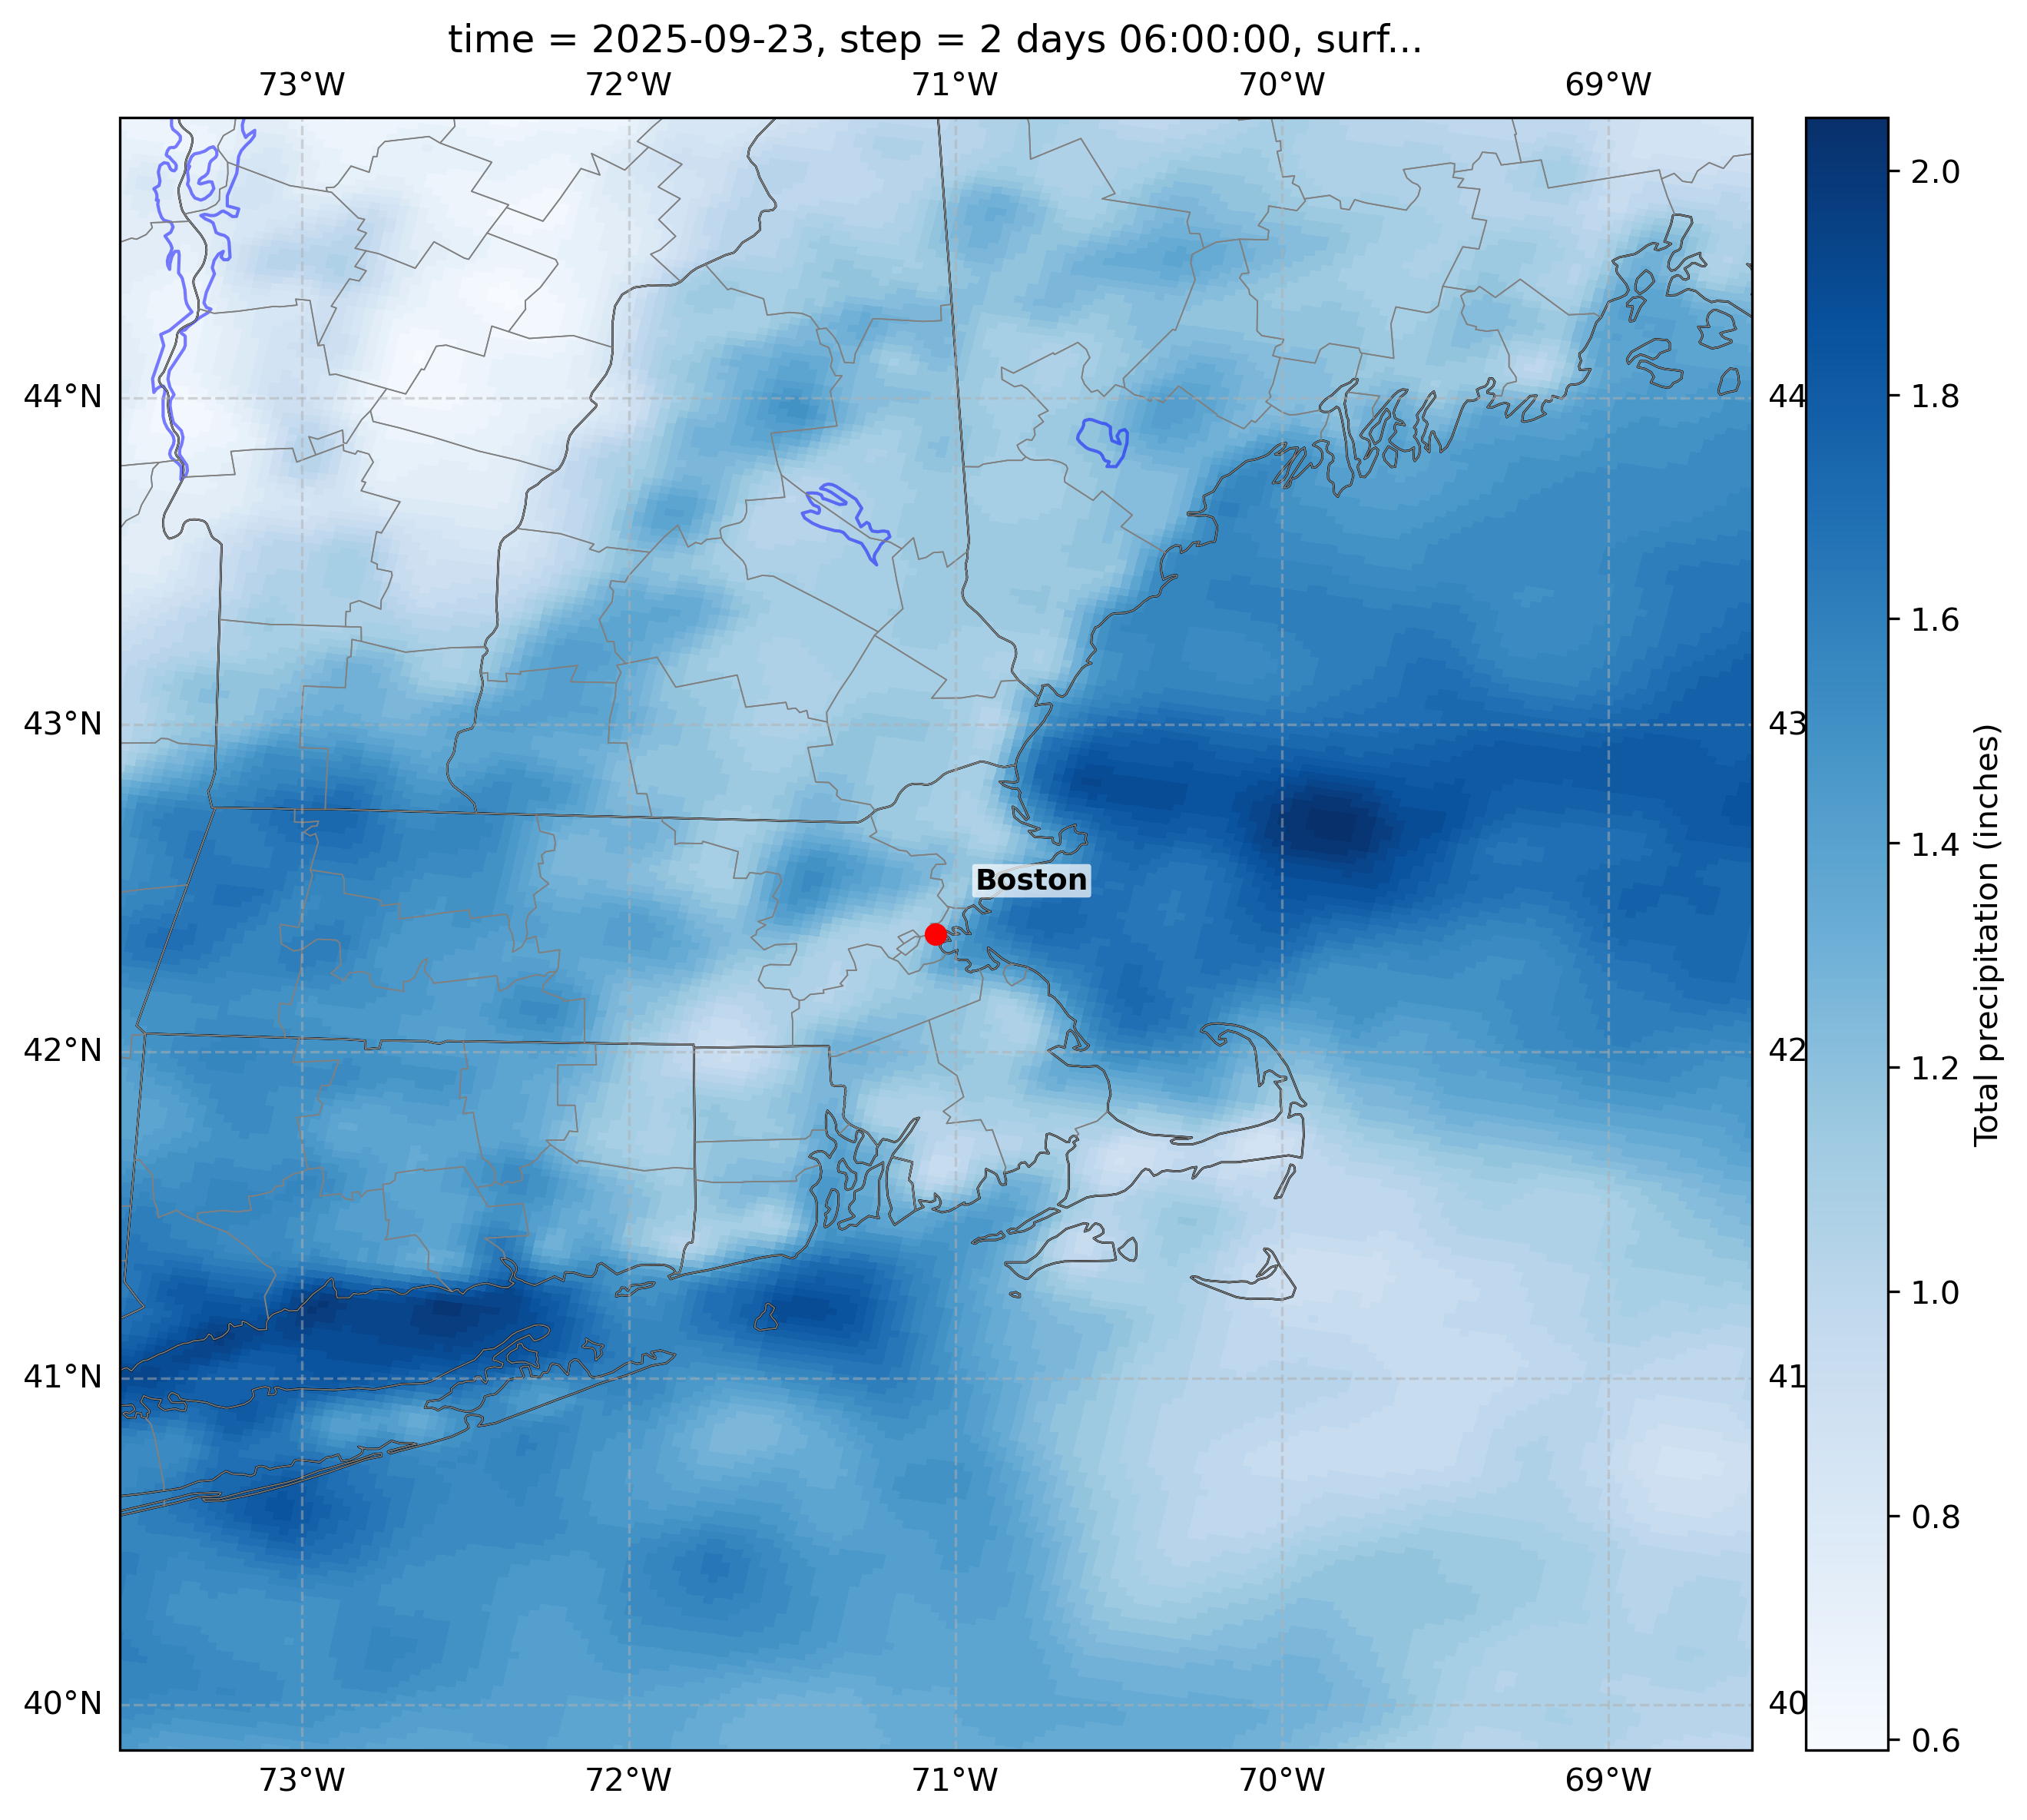

In [57]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.io import shapereader as shpreader

tpFinal = xr.open_dataset('/Users/jglarson/Downloads/blend.t00z.core.f054.co.grib2', 
                engine='cfgrib', filter_by_keys={'stepType': 'accum', 'typeOfLevel': 'surface', 'uvRelativeToGrid': 0}
                )
tpFinal = tpFinal.where((tpFinal.latitude >= 39.0) & (tpFinal.latitude <= 45.0) & (tpFinal.longitude >= 286) & (tpFinal.longitude <= 292), drop=True).tp

da_total_in = tpFinal* 0.0393701  # convert mm -> inches


# Center from points dataframe
center_lon = float(points.longitude.iloc[0])
center_lat = float(points.latitude.iloc[0])
extent = 3 - 0.5
lon0, lon1 = center_lon - extent, center_lon + extent
lat0, lat1 = center_lat - extent, center_lat + extent


# Plot with cartopy for geographic features
fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={'projection': ccrs.PlateCarree()},
                       dpi=300)
# Use xarray's built-in pcolormesh plotting (handles lat/lon coords)
c = da_total_in.plot.pcolormesh(
    ax=ax, x='longitude', y='latitude', cmap='Blues', shading='auto', add_colorbar=False, transform=ccrs.PlateCarree()
)
cb = fig.colorbar(c, ax=ax, orientation='vertical', pad=0.02)
cb.set_label('Total precipitation (inches)')

# Add geographic features
ax.add_feature(cfeature.BORDERS, linestyle='--', edgecolor='black', linewidth=0.8)
ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.6)
ax.add_feature(cfeature.COASTLINE, edgecolor='black', linewidth=0.6)
ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.5)
ax.add_feature(cfeature.LAKES, edgecolor='blue', facecolor='none', alpha=0.5)

# Add county boundaries using a shapefile
shapefile = shpreader.natural_earth(resolution='10m', category='cultural', name='admin_2_counties')
counties = shpreader.Reader(shapefile).geometries()
ax.add_geometries(counties, ccrs.PlateCarree(), edgecolor='gray', facecolor='none', linewidth=0.4)

# Set title and labels
# ax.set_title(f"{cityName} — Total precipitation (±5°) | Init: {pd.Timestamp(init_ifs).isoformat()} | fxx: {fxx_ifs[0]}–{fxx_ifs[-1]} h")
ax.set_extent([min(lon0, lon1), max(lon0, lon1), min(lat0, lat1), max(lat0, lat1)], crs=ccrs.PlateCarree())
ax.gridlines(draw_labels=True, linestyle='--', alpha=0.5)

# Add major cities (lon, lat). Use -71.0591 for Boston longitude
cities = {
    "Boston": (-71.0591, 42.3601),
    # add more: "Chicago": (-87.6298, 41.8781), ...
}

for name, (lon, lat) in cities.items():
    ax.plot(lon, lat, marker='o', color='red', markersize=6,
            transform=ccrs.PlateCarree(), zorder=6)
    ax.text(lon + 0.12, lat + 0.12, name,
            transform=ccrs.PlateCarree(), fontsize=9, fontweight='bold',
            ha='left', va='bottom', zorder=7,
            bbox=dict(boxstyle='round,pad=0.1', facecolor='white', alpha=0.7, edgecolor='none'))


plt.tight_layout()
plt.show()

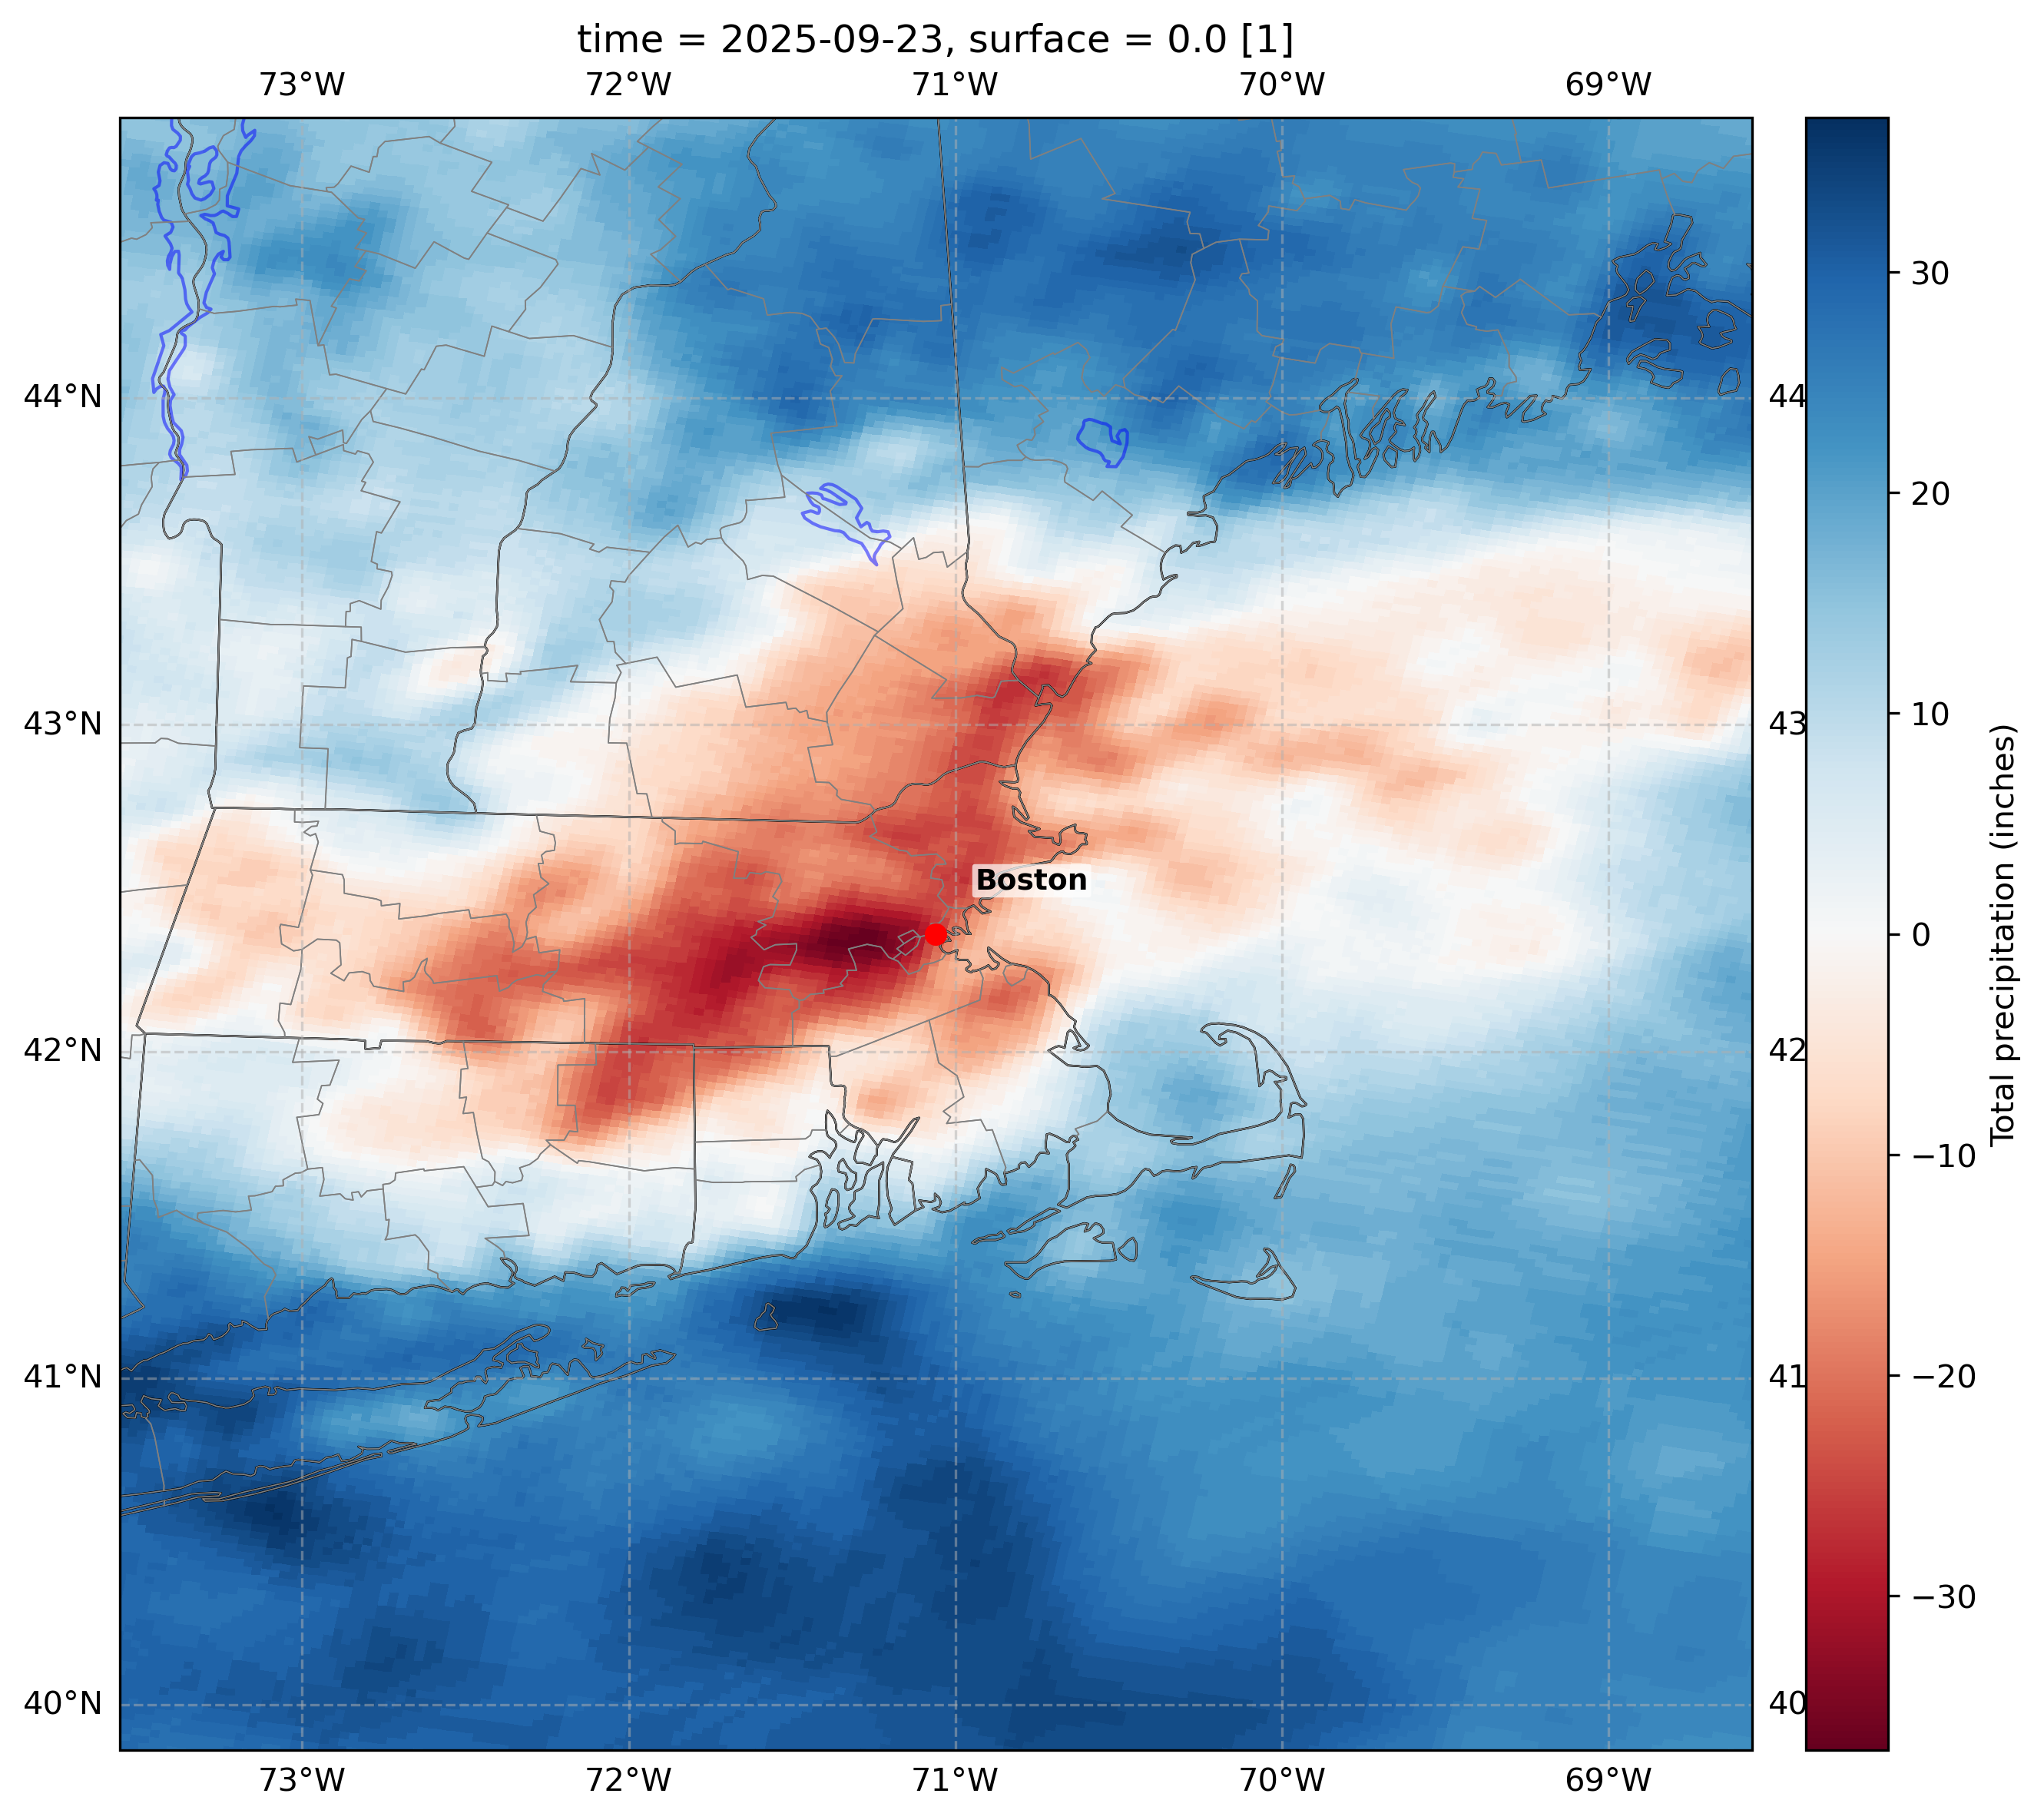

In [61]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.io import shapereader as shpreader

# tpFinal = xr.open_dataset('/Users/jglarson/Downloads/blend.t00z.core.f054.co.grib2', 
#                 engine='cfgrib', filter_by_keys={'stepType': 'accum', 'typeOfLevel': 'surface', 'uvRelativeToGrid': 0}
#                 )
# tpFinal = tpFinal.where((tpFinal.latitude >= 39.0) & (tpFinal.latitude <= 45.0) & (tpFinal.longitude >= 286) & (tpFinal.longitude <= 292), drop=True).tp

da_total_in = tpFinal - tp


# Center from points dataframe
center_lon = float(points.longitude.iloc[0])
center_lat = float(points.latitude.iloc[0])
extent = 3 - 0.5
lon0, lon1 = center_lon - extent, center_lon + extent
lat0, lat1 = center_lat - extent, center_lat + extent


# Plot with cartopy for geographic features
fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={'projection': ccrs.PlateCarree()},
                       dpi=300)
# Use xarray's built-in pcolormesh plotting (handles lat/lon coords)
c = da_total_in.plot.pcolormesh(
    ax=ax, x='longitude', y='latitude', cmap='RdBu', shading='auto', add_colorbar=False, transform=ccrs.PlateCarree()
)
cb = fig.colorbar(c, ax=ax, orientation='vertical', pad=0.02)
cb.set_label('Total precipitation (inches)')

# Add geographic features
ax.add_feature(cfeature.BORDERS, linestyle='--', edgecolor='black', linewidth=0.8)
ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.6)
ax.add_feature(cfeature.COASTLINE, edgecolor='black', linewidth=0.6)
ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.5)
ax.add_feature(cfeature.LAKES, edgecolor='blue', facecolor='none', alpha=0.5)

# Add county boundaries using a shapefile
shapefile = shpreader.natural_earth(resolution='10m', category='cultural', name='admin_2_counties')
counties = shpreader.Reader(shapefile).geometries()
ax.add_geometries(counties, ccrs.PlateCarree(), edgecolor='gray', facecolor='none', linewidth=0.4)

# Set title and labels
# ax.set_title(f"{cityName} — Total precipitation (±5°) | Init: {pd.Timestamp(init_ifs).isoformat()} | fxx: {fxx_ifs[0]}–{fxx_ifs[-1]} h")
ax.set_extent([min(lon0, lon1), max(lon0, lon1), min(lat0, lat1), max(lat0, lat1)], crs=ccrs.PlateCarree())
ax.gridlines(draw_labels=True, linestyle='--', alpha=0.5)

# Add major cities (lon, lat). Use -71.0591 for Boston longitude
cities = {
    "Boston": (-71.0591, 42.3601),
    # add more: "Chicago": (-87.6298, 41.8781), ...
}

for name, (lon, lat) in cities.items():
    ax.plot(lon, lat, marker='o', color='red', markersize=6,
            transform=ccrs.PlateCarree(), zorder=6)
    ax.text(lon + 0.12, lat + 0.12, name,
            transform=ccrs.PlateCarree(), fontsize=9, fontweight='bold',
            ha='left', va='bottom', zorder=7,
            bbox=dict(boxstyle='round,pad=0.1', facecolor='white', alpha=0.7, edgecolor='none'))


plt.tight_layout()
plt.show()

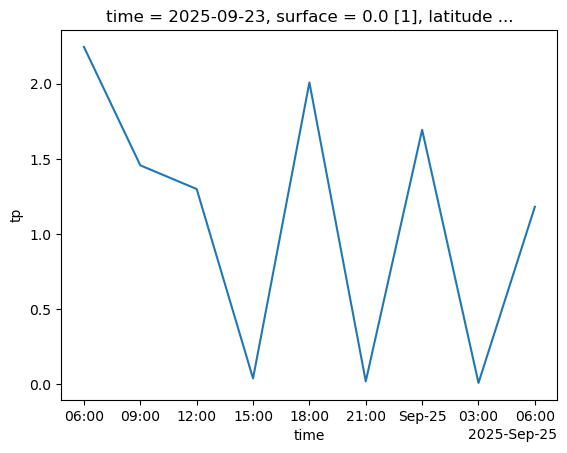

In [15]:
tp_nbm = xr.open_mfdataset(files_sorted, combine='nested', concat_dim='valid_time', engine='cfgrib', parallel=True)
(selPoint(tp_nbm.tp, points.latitude[0], points.longitude[0])*0.0393701).plot()

In [16]:
selPoint(tp_nbm.tp, points.latitude[0], points.longitude[0]).cumsum().values*0.0393701

array([2.2440958, 3.7007895, 5.000003 , 5.0400033, 7.0478783, 7.0678782,
       8.760793 , 8.770792 , 9.951896 ], dtype=float32)

In [64]:
target_lat, target_lon = 40.451685, -105.004186  # desired point

# convert target_lon to 0-360 if necessary
if target_lon < 0:
    target_lon += 360
    print(f"Converted target_lon to {target_lon}")

# lat2d, lon2d are the 2D coordinate arrays (xarray DataArray or numpy arrays)
# da is your DataArray with dims ('y','x')
# lat2d = tp_nbm['latitude']   # or separate variable
# lon2d = tp_nbm['longitude']

# compute squared distance and find index of minimum
dist = (tp_nbm['latitude'] - target_lat)**2 + (tp_nbm['longitude'] - target_lon)**2
iy, ix = np.unravel_index(dist.values.argmin(), dist.shape)

# select the point
point_value = tp_nbm.isel(y=iy, x=ix)
point_value

Converted target_lon to 254.995814


<xarray.DataArray 'tp' ()> Size: 4B
[1 values with dtype=float32]
Coordinates:
    time        datetime64[ns] 8B ...
    step        timedelta64[ns] 8B ...
    surface     float64 8B ...
    latitude    float64 8B 40.46
    longitude   float64 8B 255.0
    valid_time  datetime64[ns] 8B ...
Attributes: (12/34)
    GRIB_paramId:                             228228
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      3744965
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            accum
    ...                                       ...
    GRIB_name:                                Total Precipitation
    GRIB_shortName:                           tp
    GRIB_units:                               kg m**-2
    long_name:                                Total Precipitation
    units:                                    kg m**-2
    standard_name:                            unknown

In [ ]:
# 2 m temperature: extract, convert K->F, compute max/min for the point
t2m_nbm = H_nbm.xarray(":TMP:2 m.*:nan:nan", backend_kwargs={'decode_times': False}
                        ).herbie.pick_points(points, method="nearest")['t2m'].sel(point=0)[1:]  # skip first timestep which is included for precip only
t2m_nbm = (t2m_nbm - 273.15) * 1.8 + 32
tmax_nbm = float(t2m_nbm.max().values)
tmin_nbm = float(t2m_nbm.min().values)
init_times_nbm = convert_time_to_datetime64(t2m_nbm.time.values)
valid_times_nbm = convert_time_to_datetime64(t2m_nbm.valid_time.values)

# 10 m wind speed (HRRR exposes :WIND / si10)
si10_nbm = H_nbm.xarray(":WIND:10 m above ground:", backend_kwargs={'decode_times': False}
                            ).herbie.pick_points(points, method="nearest")['max_10si'].sel(point=0)[1:]  # skip first timestep which is included for precip only
wind_max_nbm = float(si10_nbm.max().values) * 1.94384 # convert from m/s to knots

# Total precipitation from APCP (convert mm -> in); compute 24h accumulation as in prior script
tp_nbm = H_nbm.xarray("APCP", backend_kwargs={'decode_times': False}
                        ).herbie.pick_points(points, method="nearest")['tp'].sel(point=0)
tp_nbm = tp_nbm * 0.0393701   # mm -> inches (1 mm -> 0.0393701 in)

# Subtract first timestep to get accumulation over the requested period (as in original)
tp_nbm = tp_nbm[1:] - tp_nbm[0]
precip_nbm = float(tp_nbm.max().values)

# build and print a simple table using pandas for formatting (NBM)
df = pd.DataFrame({
    "Model": ["NBM"],
    "High (°F)": [round(tmax_nbm, 2)],
    "Low (°F)": [round(tmin_nbm, 2)],
    "Precipitation (in)": [round(precip_nbm, 3)],
    "Wind Speed (kt)": [round(wind_max_nbm, 2)],
    "Model Init": [pd.Timestamp(init_times_nbm).isoformat()],
    "Valid Range": [f"{valid_times_nbm[0]} - {valid_times_nbm[-1]}"]
})

title = f"Forecasting for {cityName} (NBM)"
print(title)
print(df.to_string(index=False))


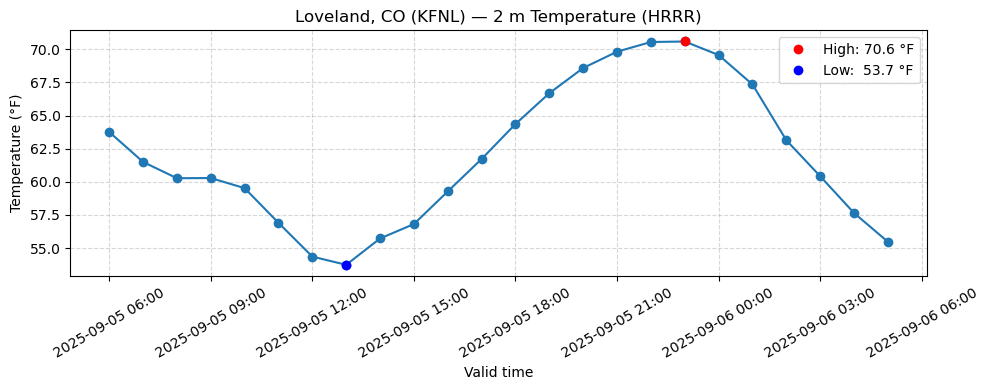

In [29]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

times = pd.to_datetime(valid_times_hrrr)  # numpy.datetime64 -> DatetimeIndex
temps = t2m_hrrr.values  # Fahrenheit values from HRRR

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(times, temps, marker='o', linestyle='-')

# highlight max/min
idx_max = int(np.nanargmax(temps))
idx_min = int(np.nanargmin(temps))
ax.plot(times[idx_max], temps[idx_max], 'ro', label=f"High: {temps[idx_max]:.1f} °F")
ax.plot(times[idx_min], temps[idx_min], 'bo', label=f"Low:  {temps[idx_min]:.1f} °F")

ax.set_title(f"{cityName} — 2 m Temperature (HRRR)")
ax.set_xlabel("Valid time")
ax.set_ylabel("Temperature (°F)")
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'))
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
plt.xticks(rotation=30)
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()

# AIFS

In [ ]:
from functions import *   # get_latest_forecast_cycle, calculate_forecast_range, convert_time_to_datetime64
from herbie import FastHerbie
import pandas as pd
import numpy as np
import xarray as xr
import warnings

# Suppress the specific FutureWarning message from cfgrib
warnings.filterwarnings(
    "ignore",
    # message="In a future version of xarray the default value for compat will change",
    message="In*",
    category=FutureWarning
)

# xr.set_options(use_new_combine_kwarg_defaults=True)

# xr.set_options(use_new_combine_kwarg_defaults=True)

# single point (longitude, latitude)
cityName = "Loveland, CO (KFNL)"
points = pd.DataFrame({"longitude": [-105.004186], "latitude": [40.451685]})
cityName = 'Kansas City, MO (KMCI)'
points = pd.DataFrame({"longitude": [-94.711], "latitude": [39.301]})

print("Fetching AIFS data...")

init_aifs = get_latest_forecast_cycle(model="AIFS")
fxx_aifs = calculate_forecast_range(init_aifs, model="AIFS")
H_aifs = FastHerbie([init_aifs], model="aifs", product="oper", fxx=fxx_aifs)

# 2 m temperature: extract and convert
t2m_aifs = H_aifs.xarray(":2t:", backend_kwargs={'decode_times': False}
                        ).herbie.pick_points(points, method="nearest")['t2m'].sel(point=0)
t2m_aifs = (t2m_aifs - 273.15) * 1.8 + 32
tmax_aifs = float(t2m_aifs.max().values)
tmin_aifs = float(t2m_aifs.min().values)
init_times_aifs = convert_time_to_datetime64(t2m_aifs.time.values)
valid_times_aifs = convert_time_to_datetime64(t2m_aifs.valid_time.values)

# Wind from components -> magnitude
u10_aifs = H_aifs.xarray(":10u:", backend_kwargs={'decode_times': False}
                        ).herbie.pick_points(points, method="nearest")['u10'].sel(point=0)
v10_aifs = H_aifs.xarray(":10v:", backend_kwargs={'decode_times': False}
                        ).herbie.pick_points(points, method="nearest")['v10'].sel(point=0)
wind_max_aifs = float((np.sqrt(u10_aifs**2 + v10_aifs**2)).max().values) * 1.94384 # Convert m/s to knots

# Total precipitation (sum over requested steps) and convert to inches
tp_aifs = H_aifs.xarray(":tp:", backend_kwargs={'decode_times': False}
                        ).herbie.pick_points(points, method="nearest")['tp'].sel(point=0)
precip_aifs = float(tp_aifs.max().values) * 0.0393701 # Convert millimeters to inches (1 m -> 39.3701 in)



Fetching AIFS data...
👨🏻‍🏭 Created directory: [/Users/jglarson/data/aifs/20250920]


TypeError: only length-1 arrays can be converted to Python scalars

In [2]:
init_aifs, fxx_aifs

(Timestamp('2025-09-20 06:00:00'), [24, 30, 36, 42, 48])

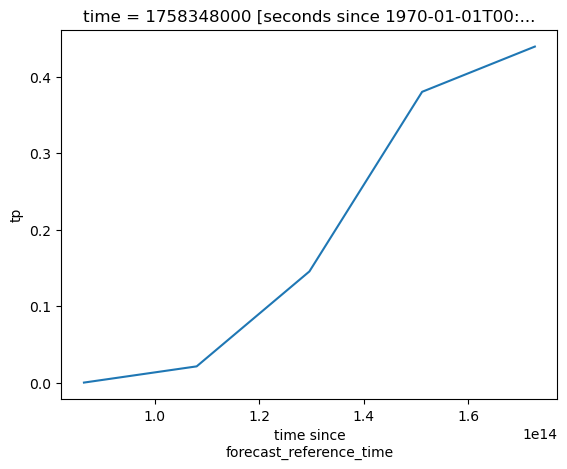

In [5]:
# Total precipitation (sum over requested steps) and convert to inches
tp_aifs = H_aifs.xarray(":tp:", backend_kwargs={'decode_times': False}
                        ).herbie.pick_points(points, method="nearest")['tp'].sel(point=0)
tp_aifs = tp_aifs - tp_aifs[0]
precip_aifs = float(tp_aifs.max().values) * 0.0393701 # Convert millimeters to inches (1 m -> 39.3701 in)
(tp_aifs * 0.0393701).plot()


In [46]:
init_aifs

Timestamp('2025-09-16 18:00:00')

In [40]:
# Create the title and the table combining both models (use the current variable names)
title = f"Forecasting for {cityName} \nValid: {str(valid_times_aifs[0])} - {str(valid_times_aifs[-1])} UTC"

data = {
    "Model": ["AIFS"],
    "High (°F)": [tmax_aifs],
    "Low (°F)": [tmin_aifs],
    "Precipitation (in)": [precip_aifs],
    "Wind Speed (kt)": [wind_max_aifs],
    "Model Init": [f"{str(init_times_aifs)} UTC"]
}

df_forecast = pd.DataFrame(data).round(2)

# Print the title and table without row numbers
print(title)
print(df_forecast.to_string(index=False))


Forecasting for Eagle, CO (KEGE) 
Valid: 2025-09-17T12 - 2025-09-18T06 UTC
Model  High (°F)  Low (°F)  Precipitation (in)  Wind Speed (kt)        Model Init
 AIFS      57.32     36.56              545.49              3.3 2025-09-16T18 UTC


# IFS

In [20]:
from functions import *   # get_latest_forecast_cycle, calculate_forecast_range, convert_time_to_datetime64
from herbie import FastHerbie
import pandas as pd
import numpy as np
import xarray as xr
import warnings

# Suppress the specific FutureWarning message from cfgrib
warnings.filterwarnings(
    "ignore",
    # message="In a future version of xarray the default value for compat will change",
    message="In*",
    category=FutureWarning
)

# xr.set_options(use_new_combine_kwarg_defaults=True)

# xr.set_options(use_new_combine_kwarg_defaults=True)

# single point (longitude, latitude)
cityName = "Loveland, CO (KFNL)"
points = pd.DataFrame({"longitude": [-105.004186], "latitude": [40.451685]})
cityName = 'Seattle, WA (KSEA)'
points = pd.DataFrame({"longitude": [-122.335], "latitude": [47.646]})

print("Fetching IFS data...")

init_ifs = get_latest_forecast_cycle(model="IFS")
fxx_ifs = calculate_forecast_range(init_ifs, model="IFS")
H_ifs = FastHerbie([init_ifs], model="ifs", product="oper", fxx=fxx_ifs)

# 2 m temperature: extract and convert
t2m_ifs = H_ifs.xarray(":2t:", backend_kwargs={'decode_times': False}
                        ).herbie.pick_points(points, method="nearest")['t2m'].sel(point=0)  
t2m_ifs = (t2m_ifs - 273.15) * 1.8 + 32
tmax_ifs = float(t2m_ifs.max().values)
tmin_ifs = float(t2m_ifs.min().values)
init_times_ifs = convert_time_to_datetime64(t2m_ifs.time.values)
valid_times_ifs = convert_time_to_datetime64(t2m_ifs.valid_time.values)

# Wind from components -> magnitude
u10_ifs = H_ifs.xarray(":10u:", backend_kwargs={'decode_times': False}
                        ).herbie.pick_points(points, method="nearest")['u10'].sel(point=0)
v10_ifs = H_ifs.xarray(":10v:", backend_kwargs={'decode_times': False}
                        ).herbie.pick_points(points, method="nearest")['v10'].sel(point=0)
wind_max_ifs = float((np.sqrt(u10_ifs**2 + v10_ifs**2)).max().values) * 1.94384 # Convert m/s to knots

# Total precipitation (sum over requested steps) and convert to inches
tp_ifs = H_ifs.xarray(":tp:", backend_kwargs={'decode_times': False}
                        ).herbie.pick_points(points, method="nearest")['tp'].sel(point=0)
tp_ifs = tp_ifs - tp_ifs[0]
precip_ifs = float(tp_ifs.max().values) * 39.3701 # Convert meters to inches (1 m -> 39.3701 in)

times_ifs = pd.to_datetime(valid_times_ifs)



Fetching IFS data...


In [18]:
init_ifs, fxx_ifs

(Timestamp('2025-09-30 00:00:00'), [30, 33, 36, 39, 42, 45, 48, 51, 54])

In [4]:

convert_time_to_datetime64(H_ifs.xarray(":tp:", backend_kwargs={'decode_times': False})['valid_time'].values)

array(['2025-09-21T06', '2025-09-21T09', '2025-09-21T12', '2025-09-21T15',
       '2025-09-21T18', '2025-09-21T21', '2025-09-22T00', '2025-09-22T03',
       '2025-09-22T06'], dtype='datetime64[h]')

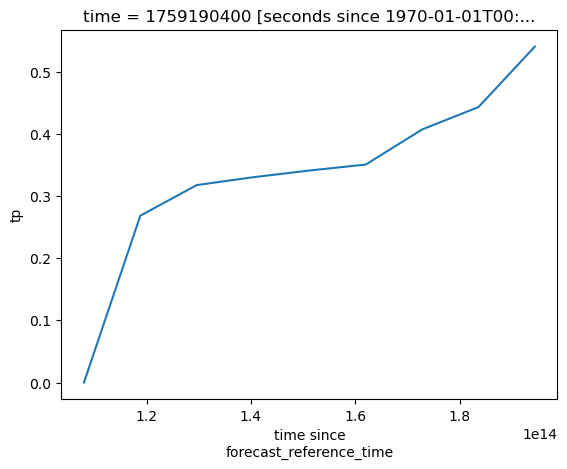

In [23]:
tp_ifs = H_ifs.xarray(":tp:", backend_kwargs={'decode_times': False}
                        ).herbie.pick_points(points, method="nearest")['tp'].sel(point=0)
tp_ifs = (tp_ifs - tp_ifs[0]) * 39.3701
# precip_ifs = float(tp_ifs.max().values) * 39.3701 # Convert meters to inches (1 m -> 39.3701 in)

tp_ifs.plot()

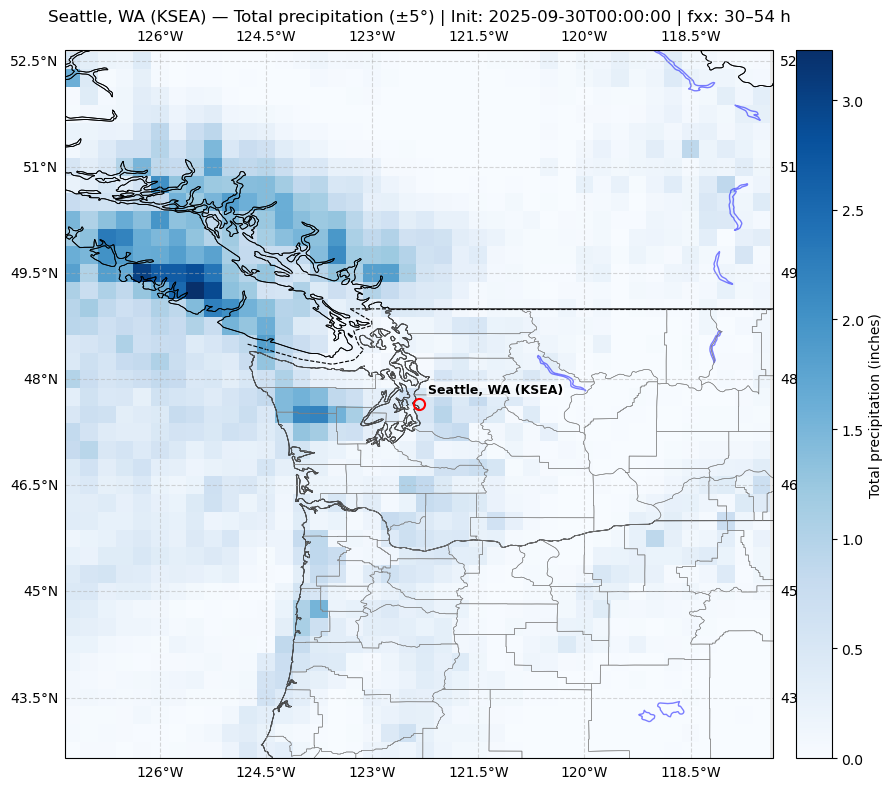

In [26]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.io import shapereader as shpreader

# Fetch gridded total precipitation for the same steps, sum over the steps and plot a subset +/-5° around the point
ds_tp = H_ifs.xarray(":tp:", backend_kwargs={'decode_times': False})
da_tp = ds_tp['tp'] if isinstance(ds_tp, xr.Dataset) else ds_tp

# Sum accumulated precipitation over the step dimension to get total (units: meters)
# da_total = da_tp.sum(dim='step')
da_total = da_tp.isel(step=-1) - da_tp.isel(step=0)  # subtract first timestep to get accumulation over the period
da_total_in = da_total * 39.3701  # Convert meters -> inches

# Center from points dataframe
center_lon = float(points.longitude.iloc[0])
center_lat = float(points.latitude.iloc[0])
lon0, lon1 = center_lon - 5.0, center_lon + 5.0
lat0, lat1 = center_lat - 5.0, center_lat + 5.0

# Normalize longitude to -180..180 if needed
if da_total_in.longitude.max() > 180:
    lons = ((da_total_in.longitude + 180) % 360) - 180
    da_total_in = da_total_in.assign_coords(longitude=lons).sortby('longitude')

# Subset using boolean indexing to avoid issues with coordinate ordering
da_sel = da_total_in.where(
    (da_total_in.longitude >= min(lon0, lon1)) & (da_total_in.longitude <= max(lon0, lon1)),
    drop=True
)
da_sel = da_sel.where(
    (da_sel.latitude >= min(lat0, lat1)) & (da_sel.latitude <= max(lat0, lat1)),
    drop=True
)

# Plot with cartopy for geographic features
fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={'projection': ccrs.PlateCarree()})
# Use xarray's built-in pcolormesh plotting (handles lat/lon coords)
c = da_sel.plot.pcolormesh(
    ax=ax, x='longitude', y='latitude', cmap='Blues', shading='auto', add_colorbar=False, transform=ccrs.PlateCarree()
)
cb = fig.colorbar(c, ax=ax, orientation='vertical', pad=0.02)
cb.set_label('Total precipitation (inches)')

# Add geographic features
ax.add_feature(cfeature.BORDERS, linestyle='--', edgecolor='black', linewidth=0.8)
ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.6)
ax.add_feature(cfeature.COASTLINE, edgecolor='black', linewidth=0.6)
ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.5)
ax.add_feature(cfeature.LAKES, edgecolor='blue', facecolor='none', alpha=0.5)

# Add county boundaries using a shapefile
shapefile = shpreader.natural_earth(resolution='10m', category='cultural', name='admin_2_counties')
counties = shpreader.Reader(shapefile).geometries()
ax.add_geometries(counties, ccrs.PlateCarree(), edgecolor='gray', facecolor='none', linewidth=0.4)

# Mark the point(s) from `points` (and label the city)
for _, row in points.iterrows():
    lon_pt = float(row.longitude)
    lat_pt = float(row.latitude)
    ax.plot(lon_pt, lat_pt, marker='o', markerfacecolor='none', markeredgecolor='red',
            markersize=8, markeredgewidth=1.5, transform=ccrs.PlateCarree(), zorder=6)
    # label using cityName (first point typically corresponds to cityName)
    ax.text(lon_pt + 0.12, lat_pt + 0.12, cityName,
            transform=ccrs.PlateCarree(), fontsize=9, fontweight='bold',
            ha='left', va='bottom', zorder=7,
            bbox=dict(boxstyle='round,pad=0.1', facecolor='white', alpha=0.7, edgecolor='none'))

# Set title and labels
ax.set_title(f"{cityName} — Total precipitation (±5°) | Init: {pd.Timestamp(init_ifs).isoformat()} | fxx: {fxx_ifs[0]}–{fxx_ifs[-1]} h")
ax.set_extent([min(lon0, lon1), max(lon0, lon1), min(lat0, lat1), max(lat0, lat1)], crs=ccrs.PlateCarree())
ax.gridlines(draw_labels=True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# IFS Ens

## Herbie

In [1]:
from functions import *   # get_latest_forecast_cycle, calculate_forecast_range, convert_time_to_datetime64
from herbie import FastHerbie
import pandas as pd
import numpy as np
import xarray as xr
import warnings

# Suppress the specific FutureWarning message from cfgrib
warnings.filterwarnings(
    "ignore",
    # message="In a future version of xarray the default value for compat will change",
    message="In*",
    category=FutureWarning
)

# xr.set_options(use_new_combine_kwarg_defaults=True)

# xr.set_options(use_new_combine_kwarg_defaults=True)

# single point (longitude, latitude)
cityName = "Loveland, CO (KFNL)"
points = pd.DataFrame({"longitude": [-105.004186], "latitude": [40.451685]})
# cityName = 'Memphis, TN (KMEM)'
# points = pd.DataFrame({"longitude": [-90.04898], "latitude": [35.14953]})
cityName = 'Seattle, WA (KSEA)'
points = pd.DataFrame({"longitude": [-122.3088], "latitude": [47.9808]})
cityName = 'Savannah, GA (KSAV)'
points = pd.DataFrame({"longitude": [-81.2], "latitude": [32.128]})

print("Fetching EPS data...")

init_eps = get_latest_forecast_cycle(model="IFS")
fxx_eps = calculate_forecast_range(init_eps, model="IFS")  
fxx_eps = [fxx_eps[0], fxx_eps[-1]]  # only first and last step for ensemble mean
H_eps_init = FastHerbie([init_eps], model="ifs", product="enfo", fxx=[fxx_eps[0]])
H_eps_end = FastHerbie([init_eps], model="ifs", product="enfo", fxx=[fxx_eps[-1]])
init_eps, fxx_eps


Fetching EPS data...


(Timestamp('2025-10-06 12:00:00'), [18, 42])

In [2]:
# H_ifs.inventory(":tp:")
# ds = H_ifs.xarray(":tp:sfc:[1-9][0-9]?:g:", backend_kwargs={'decode_times': False}
#                   ).herbie.pick_points(points, method="nearest")['tp'].sel(point=0)

ds_init = H_eps_init.xarray(":tp:sfc:[1-9][0-9]?:g:", backend_kwargs={'decode_times': False}
                  ).herbie.pick_points(points, method="nearest")['tp'].sel(point=0)
ds_end = H_eps_end.xarray(":tp:sfc:[1-9][0-9]?:g:", backend_kwargs={'decode_times': False}
                  ).herbie.pick_points(points, method="nearest")['tp'].sel(point=0)

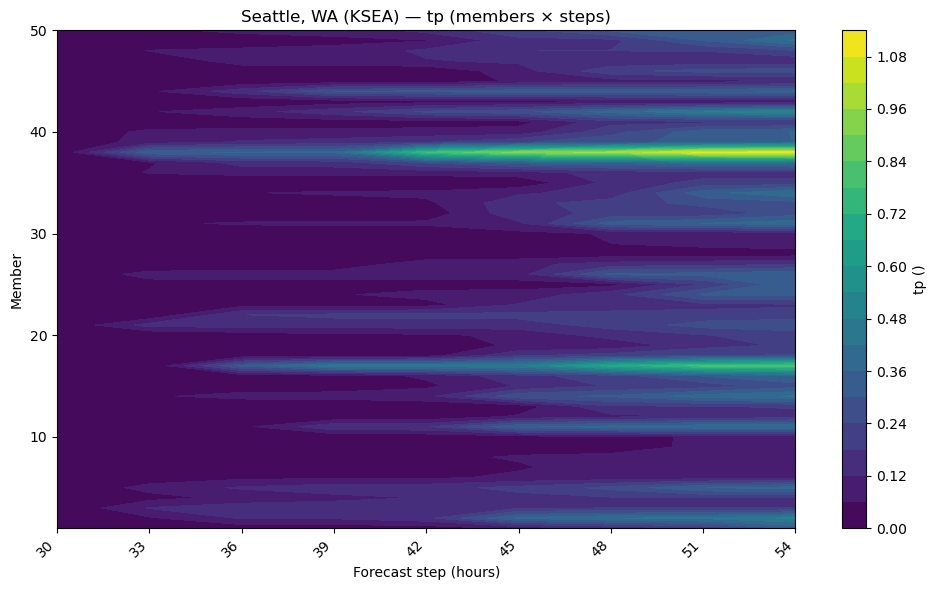

In [18]:
# plot ds with 'step' on the x-axis and ensemble 'member' (number) on the y-axis
# ds has dims (step, number) -> transpose for contour routines so rows=members, cols=steps
import matplotlib.pyplot as plt

# tp_eps = ds
dsAccum = (ds - ds[0,:]) * 39.3701 
# precip_ifs = float(tp_eps.max().values) * 39.3701 # Convert meters to inches (1 m -> 39.3701 in)

steps = np.array([int(s / np.timedelta64(1, 'h')) for s in dsAccum.step.values])  # step in hours
members = dsAccum.number.values  # ensemble member index

Z = dsAccum.values.T  # shape (members, steps)

fig, ax = plt.subplots(figsize=(10, 6))
cf = ax.contourf(steps, members, Z, levels=20, cmap="viridis")
cbar = fig.colorbar(cf, ax=ax)
cbar.set_label(f"{dsAccum.attrs.get('long_name', dsAccum.name)} ({dsAccum.attrs.get('units','')})")

ax.set_xlabel("Forecast step (hours)")
ax.set_ylabel("Member")
ax.set_title(f"{cityName} — {dsAccum.name} (members × steps)")
ax.set_xticks(steps)
ax.set_xticklabels([str(int(h)) for h in steps], rotation=45, ha='right')

plt.tight_layout()
plt.show()

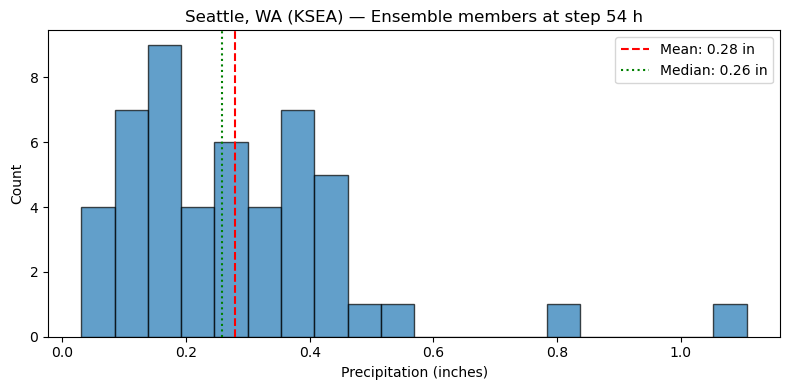

In [ ]:
import numpy as np

# Histogram of ensemble member accumulated precipitation at the last step

# select last step (equivalent to dsAccum[-1])
dsAccum = (ds - ds[0,:]) * 39.3701 
arr = dsAccum.isel(step=-1).values.flatten()
arr = arr[~np.isnan(arr)]

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(arr, bins=20, color='C0', edgecolor='k', alpha=0.7)

mean = np.nanmean(arr)
median = np.nanmedian(arr)
ax.axvline(mean, color='r', linestyle='--', label=f"Mean: {mean:.2f} in")
ax.axvline(median, color='g', linestyle=':', label=f"Median: {median:.2f} in")

last_step = int(steps[-1]) if 'steps' in globals() else -1
ax.set_title(f"{cityName} — Accumulated Precipitation")
ax.set_xlabel("Precipitation (inches)")
ax.set_ylabel("Count")
ax.legend()
plt.tight_layout()
plt.show()

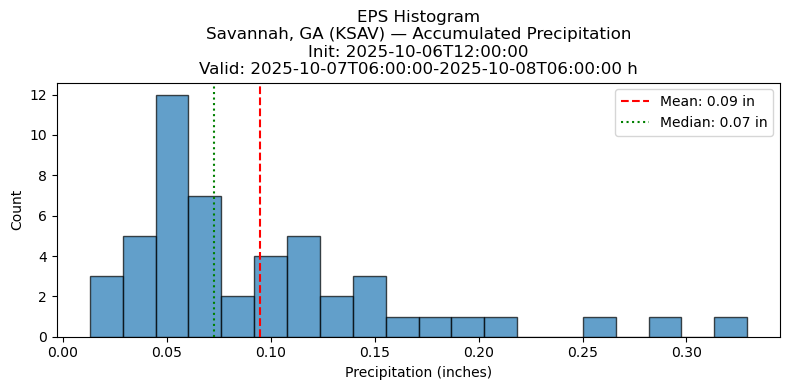

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Histogram of ensemble member accumulated precipitation at the last step

# select last step (equivalent to dsAccum[-1])
dsAccum = (ds_end - ds_init) * 39.3701
arr = dsAccum.values.flatten()
arr = arr[~np.isnan(arr)]

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(arr, bins=20, color='C0', edgecolor='k', alpha=0.7)

mean = np.nanmean(arr)
median = np.nanmedian(arr)
ax.axvline(mean, color='r', linestyle='--', label=f"Mean: {mean:.2f} in")
ax.axvline(median, color='g', linestyle=':', label=f"Median: {median:.2f} in")

last_step = int(steps[-1]) if 'steps' in globals() else -1
ax.set_title(f"EPS Histogram\n{cityName} — Accumulated Precipitation\nInit: {pd.Timestamp(init_eps).isoformat()}\nValid: {pd.Timestamp(convert_time_to_datetime64(ds_init.valid_time.values)).isoformat()}-{pd.Timestamp(convert_time_to_datetime64(ds_end.valid_time.values)).isoformat()} h")
ax.set_xlabel("Precipitation (inches)")
ax.set_ylabel("Count")
ax.legend()
plt.tight_layout()
plt.show()

In [10]:
pd.Timestamp(init_eps).isoformat()

'2025-10-02T12:00:00'

In [17]:
# ds_end - ds_init
# ds_end.valid_time.values
pd.Timestamp(convert_time_to_datetime64(ds_init.valid_time.values)).isoformat()

'2025-10-03T06:00:00'

In [36]:
init_times_eps = convert_time_to_datetime64(ds_init.time.values)
valid_time_init_eps = convert_time_to_datetime64(ds_init.valid_time.values)
valid_time_end_eps = convert_time_to_datetime64(ds_end.valid_time.values)

init_times_eps, str(valid_time_init_eps), valid_time_end_eps
# # Pack EPS metrics
# eps_metrics = {
#     "tmax_f": np.nan,  # round(tmax_eps, 1),
#     "tmin_f": np.nan,  # round(tmin_eps, 1),
#     "wind_max_kt": np.nan,  # round(wind_max_eps, 1),
#     "precip_in": round(precip_eps, 2),
#     "init_time_utc": pd.Timestamp(init_times_eps[0]).isoformat() if hasattr(init_times_eps, "__len__") else str(init_times_eps),
#     "valid_range_utc": [str(valid_times_eps[0]), str(valid_times_eps[-1])]


(np.datetime64('2025-09-30T00','h'),
 '2025-10-01T06',
 np.datetime64('2025-10-02T06','h'))

## ECMWF

In [ ]:
from ecmwf.opendata import Client

client = Client(source="ecmwf")

parameters = ['2t']#,'tp']
# filename = 'medium-ens-2t.grib'
# filename

client.retrieve(
    # time=0,
    stream="enfo",
    type="em",
    step=24,
    # param=parameters,
    target="medium-ens-2t.grib2",
)


In [11]:
import xarray as xr
xr.open_dataset("medium-ens-2t.grib2", engine="cfgrib")

skipping variable: paramId==10 shortName='ws'
Traceback (most recent call last):
  File "/Users/jglarson/miniconda3/envs/weather-output/lib/python3.13/site-packages/cfgrib/dataset.py", line 725, in build_dataset_components
    dict_merge(variables, coord_vars)
    ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/jglarson/miniconda3/envs/weather-output/lib/python3.13/site-packages/cfgrib/dataset.py", line 641, in dict_merge
    raise DatasetBuildError(
    ...<2 lines>...
    )
cfgrib.dataset.DatasetBuildError: key present and new value is different: key='isobaricInhPa' value=Variable(dimensions=('isobaricInhPa',), data=array([850., 500., 250.])) new_value=Variable(dimensions=('isobaricInhPa',), data=array([850., 250.]))
skipping variable: paramId==156 shortName='gh'
Traceback (most recent call last):
  File "/Users/jglarson/miniconda3/envs/weather-output/lib/python3.13/site-packages/cfgrib/dataset.py", line 725, in build_dataset_components
    dict_merge(variables, coord_vars)
    ~~~~

<xarray.Dataset> Size: 17MB
Dimensions:        (isobaricInhPa: 3, latitude: 721, longitude: 1440)
Coordinates:
    time           datetime64[ns] 8B ...
    step           timedelta64[ns] 8B ...
  * isobaricInhPa  (isobaricInhPa) float64 24B 850.0 500.0 250.0
  * latitude       (latitude) float64 6kB 90.0 89.75 89.5 ... -89.5 -89.75 -90.0
  * longitude      (longitude) float64 12kB -180.0 -179.8 -179.5 ... 179.5 179.8
    valid_time     datetime64[ns] 8B ...
    meanSea        float64 8B ...
Data variables:
    t              (isobaricInhPa, latitude, longitude) float32 12MB ...
    msl            (latitude, longitude) float32 4MB ...
Attributes:
    GRIB_edition:            2
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-09-16T14:58 GRIB to CDM+CF via cfgrib-0.9.1...

# Preivous day forecasts - HRRR

In [16]:
# Minimal script: fetch HRRR forecasts initialized on the prior day for the previous two target dates
# Paste into a new .py or notebook cell and run.

from datetime import timezone
import pandas as pd
from herbie import FastHerbie
from functions import calculate_forecast_range
import json, pprint

# single point to summarize (lon, lat)
points = pd.DataFrame({"longitude": [-105.004186], "latitude": [40.451685]})
site_name = "Loveland, CO (KFNL)"

def init_for_target_date(target_date):
    """For a target date (pd.Timestamp, UTC midnight), return the HRRR init on the prior day (18Z)."""
    prior_day = (target_date - pd.Timedelta(days=1))#.tz_localize('UTC')
    init = prior_day.replace(hour=18, minute=0, second=0, microsecond=0)
    # return tz-naive to match existing codebase expectations
    return pd.Timestamp(init).tz_localize(None)

def fetch_hrrr_metrics(init_ts):
    """Fetch HRRR for a given init (pd.Timestamp tz-naive) and return summary metrics."""
    try:
        fxx = calculate_forecast_range(init_ts, model="HRRR")
        H = FastHerbie([init_ts], model="hrrr", product="sfc", fxx=fxx)

        # 2 m temperature (K -> F), skip first timestep as in existing workflows
        t2m = H.xarray("TMP:2 m above", backend_kwargs={'decode_times': False}
                       ).herbie.pick_points(points, method="nearest")['t2m'].sel(point=0)[1:]
        t2m_f = (t2m - 273.15) * 1.8 + 32
        tmax = float(t2m_f.max().values)
        tmin = float(t2m_f.min().values)

        # 10 m wind (HRRR :WIND / si10) -> max in knots
        si10 = H.xarray(":WIND", backend_kwargs={'decode_times': False}
                        ).herbie.pick_points(points, method="nearest")['max_10si'].sel(point=0)[1:]
        wind_max_kt = float(si10.max().values) * 1.94384

        # accumulated precipitation (APCP), convert to inches (match existing code)
        tp = H.xarray("APCP", backend_kwargs={'decode_times': False}
                      ).herbie.pick_points(points, method="nearest")['tp'].sel(point=0)
        tp_in = tp * 0.0393701
        # subtract first timestep to get step-accumulation over the requested window
        tp_step = tp_in[1:] - tp_in[0]
        precip_in = float(tp_step.max().values)

        return {
            "init_utc": str(init_ts),
            "tmax_f": round(tmax, 2),
            "tmin_f": round(tmin, 2),
            "wind_max_kt": round(wind_max_kt, 2),
            "precip_in": round(precip_in, 3),
        }
    except Exception as exc:
        return {"init_utc": str(init_ts), "error": str(exc)}

def main_previous_two_days():
    # target dates are UTC midnights for yesterday and day-before-yesterday
    now_utc = pd.Timestamp.utcnow().normalize()
    targets = [now_utc - pd.Timedelta(days=1), now_utc - pd.Timedelta(days=2)]

    results = {}
    for tgt in targets:
        init_ts = init_for_target_date(tgt).tz_localize(None)
        print(f"Requesting HRRR init {init_ts} for target date {tgt.date()}")
        results[str(tgt.date())] = fetch_hrrr_metrics(init_ts)

    return results

if __name__ == "__main__":
    metrics = main_previous_two_days()
    pprint.pprint(metrics)
    print(json.dumps(metrics, indent=2))

Requesting HRRR init 2025-09-14 18:00:00 for target date 2025-09-15
👨🏻‍🏭 Created directory: [/Users/jglarson/data/hrrr/20250914]
Requesting HRRR init 2025-09-13 18:00:00 for target date 2025-09-14
👨🏻‍🏭 Created directory: [/Users/jglarson/data/hrrr/20250913]
{'2025-09-14': {'init_utc': '2025-09-13 18:00:00',
                'precip_in': 0.171,
                'tmax_f': 73.51,
                'tmin_f': 52.62,
                'wind_max_kt': 14.13},
 '2025-09-15': {'init_utc': '2025-09-14 18:00:00',
                'precip_in': 0.001,
                'tmax_f': 84.48,
                'tmin_f': 47.94,
                'wind_max_kt': 17.0}}
{
  "2025-09-15": {
    "init_utc": "2025-09-14 18:00:00",
    "tmax_f": 84.48,
    "tmin_f": 47.94,
    "wind_max_kt": 17.0,
    "precip_in": 0.001
  },
  "2025-09-14": {
    "init_utc": "2025-09-13 18:00:00",
    "tmax_f": 73.51,
    "tmin_f": 52.62,
    "wind_max_kt": 14.13,
    "precip_in": 0.171
  }
}


Timestamp('2025-09-16 00:00:00+0000', tz='UTC')